# Гибрид AODV для подвижной Mesh-сети LoRa

Продолжение исследования `mesh_routing_aodv.ipynb`. Разделы 0–9 общие: модель, AODV, топологии нашего кейса, метрики. Новое — разделы 10–12.

**Откуда идея.** Исследование AODV показало две вещи.
1. Узкое место AODV на LoRa — поиск маршрута затоплением RREQ для каждого нового получателя. Пока идёт поиск, пакет ждёт, отсюда задержка 4–5 с.
2. После доработок (`aodv_lora`) AODV доставляет столько же, сколько эталон Дейкстры с полной картой сети. Остаток потерь (6–7 %) — моменты, когда пути до получателя нет вообще. Эталон их тоже теряет, потому что работает по правилу «отправил сейчас или потерял».

Но у нас есть 20 секунд на доставку, а узлы двигаются, и разорванная сеть за эти секунды часто снова соединяется.

**Гибрид = `aodv_lora` + два механизма:**
- **первый пакет едет внутри RREQ** — данные доставляются уже во время поиска маршрута;
- **«храни и неси»** — если пути нет, пакеты не теряются, а ждут у узла до срока. Как только узел слышит нового соседа, он снова ищет путь.

**Цель** — доставлять больше, чем эталон Дейкстры, при тех же требованиях: до 20 подвижных узлов, потери ≤ 10 %, задержка ≤ 20 с, ОЗУ 200 кБ, ПЗУ ≤ 100 000 перезаписей за 5 лет.

**Как пользоваться.** *Kernel → Restart & Run All*. Результаты лежат в `results/hybrid/*.csv`, прогон занимает около минуты. Полный пересчёт — `RERUN = True` в разделе 11.

In [1]:
# ⚙️ Требования к подвижному случаю (theory/fix, 21.10.2026)
N_NODES_MAX = 20            # до 20 подвижных узлов
LOSS_MAX = 0.10             # потери не больше 10 %
DEADLINE_S = 20.0           # доставка не дольше 20 с
RAM_MAX_B = 200 * 1024      # ОЗУ 200 кБ
ROM_MAX_B = 500 * 1024      # ПЗУ 500 кБ
FLASH_WRITES_MAX = 100_000  # перезаписей ПЗУ за 5 лет непрерывной работы

METHOD_COLORS = {"flooding": "#1c7ed6", "dijkstra": "#e8590c", "dp_hoplimit": "#2f9e44",
                 "aodv_rfc": "#ae3ec9", "aodv_rfc_hello": "#f783ac", "aodv_lora": "#f59f00"}

## 0. Допущения модели

Данные приближены к реальным: время в эфире считается по формуле Semtech для LoRa, токи потребления радио — по данным Semtech для SX1262, микроконтроллера — ориентировочные для nRF52840 или ESP32.

| № | Допущение | Как реализовано |
|---|---|---|
| 1 | Одна частота и один канал в пределах одного сегмента | Все узлы делят общий эфир. Если два кадра перекрываются у приёмника, оба теряются |
| 2 | Связь полудуплексная | Пока узел передаёт, он не принимает. Начало своей передачи портит текущий приём |
| 3 | Стоимость ребра — время передачи по нему | Стоимость перехода = (ToA кадра + время обработки) × ETX канала. Физическое распространение d/c ≈ 3 мкс/км пренебрежимо мало и не учитывается |
| 4 | Время обработки пакета на микроконтроллере — фиксированная величина | `McuConfig`: обработка принятого кадра `t_rx_proc_s` и подготовка кадра к передаче `t_tx_prep_s`. MCU выполняет задачи по одной: пока он занят, следующий пакет ждёт |
| 5 | Связь есть, если узлы ближе радиуса R | Модель «единичного диска»; качество канала падает с расстоянием, ETX = 1/p² |
| 6 | Bluetooth-участок (телефон ↔ узел) не моделируется | Пакеты появляются в очереди узла-источника. Участок Bluetooth не занимает эфир LoRa |

**Режимы узла:** 1 — дежурный приём, 2 — передача, 3* — сон (необязательный, по умолчанию выключен).

**Ограничения узла:** энергия, память, эфирное время.

In [2]:
import math, heapq, random, bisect, itertools
from collections import deque, OrderedDict, Counter
from dataclasses import dataclass, field, replace
from typing import Optional

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

## 1. Радио LoRa и время в эфире (ToA) ⚙️

Радиомодуль — **Semtech SX1262**: SF5…SF12, мощность до +22 dBm. Время в эфире считается по формуле из даташита SX1261/2 (раздел 6.1.4 «LoRa Time-on-Air»):

$$T_{sym} = \frac{2^{SF}}{BW}$$

Для SF7…SF12:
$$N = (n_{preamble} + 4{,}25) + 8 + \left\lceil \frac{\max(8PL + 16\,CRC - 4SF + 8 + 20\,H,\ 0)}{4\,(SF - 2\,LDRO)} \right\rceil (CR + 4)$$

Для SF5 и SF6:
$$N = (n_{preamble} + 6{,}25) + 8 + \left\lceil \frac{\max(8PL + 16\,CRC - 4SF + 20\,H,\ 0)}{4\,SF} \right\rceil (CR + 4)$$

$$ToA = N \cdot T_{sym}$$

Обозначения:
- PL — длина кадра в байтах;
- H = 1 при явном заголовке;
- CRC = 1, если CRC включён;
- CR = 1…4 (4/5…4/8);
- LDRO = 1 при оптимизации низкой скорости. Включается автоматически при $T_{sym}$ ≥ 16,38 мс: SF11 и SF12 на BW 125 кГц.

Для SF7…SF12 результат совпадает с формулой для SX127x. Пример: SF7, BW 125 кГц, 20 байт — 56,6 мс.

**Токи SX1262**, режим DC-DC:
- передача +22 dBm — 118 мА;
- приём LoRa, BW 125 кГц — 4,6 мА;
- сон с сохранением конфигурации — порядка 0,6 мкА (ориентировочно).

Источники: [Semtech SX1262](https://www.semtech.com/products/wireless-rf/lora-connect/sx1262), [руководство EBYTE E22](https://cdn.hackaday.io/files/1614916909230944/E22_Usermanual_EN_v1.10.pdf). Для модуля E22-900M22S там указаны 119 мА на передачу, 5,0 мА на приём и 185 нА в выключенном состоянии.

При меньшей мощности передачи или в режиме LDO возьмите токи из таблиц даташита своего модуля.

In [3]:
@dataclass
class RadioConfig:
    """⚙️ Параметры радио: Semtech SX1262."""
    chip: str = "SX1262"
    sf: int = 7                      # spreading factor, 5..12
    bw_hz: float = 125_000           # полоса, Гц
    cr: int = 1                      # 1..4 -> 4/5..4/8
    preamble_symbols: int = 8
    explicit_header: bool = True
    crc_on: bool = True
    low_dr_optimize: Optional[bool] = None   # None = авто (T_sym >= 16,38 мс)
    voltage_v: float = 3.3
    tx_power_dbm: int = 22
    i_tx_ma: float = 118.0           # передача +22 dBm, DC-DC
    i_rx_ma: float = 4.6             # дежурный приём LoRa, BW 125 кГц, DC-DC
    i_sleep_ma: float = 0.0006       # сон с сохранением конфигурации, ~0,6 мкА (ориентировочно)


def lora_toa(payload_bytes: int, r: RadioConfig) -> float:
    """Время в эфире кадра LoRa для SX126x, с (даташит SX1261/2, раздел 6.1.4)."""
    assert 5 <= r.sf <= 12, "SX1262 поддерживает SF5..SF12"
    t_sym = (2 ** r.sf) / r.bw_hz
    ldro = r.low_dr_optimize if r.low_dr_optimize is not None else (t_sym >= 0.01638)
    h = 1 if r.explicit_header else 0
    crc = 1 if r.crc_on else 0
    if r.sf in (5, 6):
        n_pre = r.preamble_symbols + 6.25
        num = 8 * payload_bytes + 16 * crc - 4 * r.sf + 20 * h
        den = 4 * r.sf
    else:
        n_pre = r.preamble_symbols + 4.25
        num = 8 * payload_bytes + 16 * crc - 4 * r.sf + 8 + 20 * h
        den = 4 * (r.sf - 2 * int(ldro))
    n_payload = 8 + math.ceil(max(num, 0) / den) * (r.cr + 4)
    return (n_pre + n_payload) * t_sym


assert abs(lora_toa(20, RadioConfig(sf=7)) - 0.05658) < 1e-4   # контрольное значение 56,6 мс


# Справочная таблица ToA, мс
pd.DataFrame(
    {f"{pl} байт": [round(lora_toa(pl, RadioConfig(sf=sf)) * 1000, 1) for sf in range(5, 13)]
     for pl in (6, 20, 32, 64)},
    index=[f"SF{sf}, BW 125 кГц" for sf in range(5, 13)],
)

,6 байт,20 байт,32 байт,64 байт
"SF5, BW 125 кГц",10.8,17.2,23.6,40.3
"SF6, BW 125 кГц",19.1,31.9,42.1,67.7
"SF7, BW 125 кГц",36.1,56.6,71.9,118.0
"SF8, BW 125 кГц",62.0,102.9,133.6,215.6
"SF9, BW 125 кГц",123.9,185.3,246.8,390.1
"SF10, BW 125 кГц",247.8,370.7,452.6,698.4
"SF11, BW 125 кГц",495.6,741.4,987.1,1560.6
"SF12, BW 125 кГц",991.2,1318.9,1810.4,2793.5


## 2. Логика узла и ограничения ⚙️

### Состояния узла

| Состояние | Что делает узел | Ток |
|---|---|---|
| **RX** — дежурный приём | Слушает эфир и принимает кадры. Каждый принятый кадр передаётся микроконтроллеру на обработку | `i_rx_ma` |
| **TX** — передача | Передаёт один кадр длительностью ToA, ничего не принимает (полудуплекс) | `i_tx_ma` |
| **SLEEP** — сон (3*, по желанию) | Не принимает и не передаёт. Просыпается по расписанию: период `sleep_period_s`, доля бодрствования `awake_fraction` | `i_sleep_ma` |
| **OFF** — узел пропал | Выключен сценарием динамики. Очередь, кэш и таблицы стираются (энергозависимая память) | 0 |
| **DEAD** — батарея исчерпана | Узел выключен навсегда | 0 |

### Переходы

```
           кадр в очереди, канал свободен,          конец кадра
           лимит эфира не превышен
   RX ───────────────────────────────────▶ TX ─────────────────▶ RX (или SLEEP, если пора спать)
   │ ▲
   │ └── пробуждение по расписанию ── SLEEP ◀── время сна (только если sleep_enabled)
   │
   └── сценарий динамики ──▶ OFF ──▶ RX (узел вернулся)
   любое состояние ── энергия исчерпана ──▶ DEAD
```

### Микроконтроллер (MCU)

Радио SX1262 только принимает и передаёт кадры. Всё остальное делает микроконтроллер, и на это уходит время.

- **Обработка принятого кадра** — `t_rx_proc_s`. MCU получает прерывание, читает кадр из буфера радио по SPI, разбирает заголовок, проверяет кэш и принимает решение. У LoRa нет аппаратной фильтрации адресов, поэтому MCU обрабатывает и чужие кадры, которые услышал узел.
- **Подготовка кадра к передаче** — `t_tx_prep_s`: сформировать заголовок, записать кадр в буфер радио, дать команду на передачу. Это касается и DATA, и ACK.
- **Одна задача за раз.** Пока MCU занят, следующая задача ждёт. Очередь задач ограничена `mcu.queue_capacity` — это тоже ограничение памяти. При переполнении кадр теряется (`mcu_overflow`).
- **Энергия MCU** — `i_active_ma` во время задач и `i_idle_ma` в остальное время, пока узел включён. Энергия узла = радио + MCU.

Готовые профили — в `MCU_PRESETS`. Значения ориентировочные: на реальной плате времена лучше измерить, например переключая GPIO и глядя на осциллограф.

### Обработка принятого кадра (после окончания приёма и обработки на MCU)

1. **ACK для меня** — снять ожидание подтверждения и передать следующий кадр из очереди.
2. **DATA, затопление** — если ID пакета уже есть в кэше, отбросить дубликат. Если узел — получатель, доставить. Иначе, если `hop_limit > 1`, поставить копию с `hop_limit − 1` в очередь после случайной задержки `flood_jitter_s`.
3. **DATA, адресная передача** (Дейкстра, DP) — кадр не мне: игнорировать, но он всё равно занимал приёмник. Кадр мне: сразу отправить ACK. Если это дубликат (потерялся наш ACK), дальше не пересылать. Если узел — получатель, доставить. Иначе переслать следующему узлу маршрута, если `hop_limit > 1`; если нет — пакет отброшен, эфир потрачен впустую.

### Передача кадра

1. Взять первый кадр из очереди (FIFO).
2. **Подготовка на MCU** — `t_tx_prep_s`, плюс ожидание, если MCU занят.
3. **Лимит эфира**: если за последние `duty_cycle_window_s` секунд узел уже занимал эфир больше `duty_cycle_limit`, отложить передачу.
4. **Прослушивание перед передачей** (CSMA): если узел сейчас слышит чужую передачу, подождать случайное время `csma_backoff_s`. Не больше `csma_max_attempts` раз, затем передавать всё равно.
5. Передать. Для адресного кадра ждать ACK `t_rx_proc + t_tx_prep + ToA(ACK) + ack_guard_s`. Без ACK повторить до `max_retries` раз, затем отбросить пакет с причиной «обрыв канала».

### Ограничения узла

| Ограничение | Параметр | Что происходит при нарушении |
|---|---|---|
| **1. Энергия** | `battery_j` — запас энергии, Дж | Расход = радио (время в каждом состоянии × ток × напряжение) + MCU (активное время и простой). Энергия кончилась — узел переходит в DEAD |
| **2. Память** | `queue_capacity` — очередь на передачу, пакетов | Очередь полна — новый пакет отброшен (`queue_overflow`) |
| | `mcu.queue_capacity` — очередь задач MCU | Кадр, пришедший при полной очереди MCU, теряется (`mcu_overflow`) |
| | `seen_cache_capacity` — кэш ID виденных пакетов | Кэш LRU: старые ID вытесняются, и узел может повторно переслать уже виденный пакет |
| **3. Эфирное время** | `duty_cycle_limit`, `duty_cycle_window_s` | Передача откладывается, пока доля эфира в окне не опустится ниже лимита. В диапазоне EU868 по правилам 1 % в час. По умолчанию здесь 10 % в окне 60 с, чтобы ограничение было заметно на коротком прогоне |

In [4]:
@dataclass
class McuConfig:
    """⚙️ Микроконтроллер: время обработки и потребление (допущение 4)."""
    name: str = "nRF52840"
    t_rx_proc_s: float = 0.004         # обработка принятого кадра, с
    t_tx_prep_s: float = 0.002         # подготовка кадра к передаче (DATA и ACK), с
    queue_capacity: int = 8            # очередь задач MCU (ограничение памяти)
    i_active_ma: float = 3.3           # ток во время обработки
    i_idle_ma: float = 0.003           # ток в простое, узел включён


# Ориентировочные профили; замените измерениями своей платы
MCU_PRESETS = {
    "nRF52840":  McuConfig("nRF52840 (RAK4631)", 0.004, 0.002, 8, 3.3, 0.003),       # 64 МГц, System ON idle
    "ESP32-S3":  McuConfig("ESP32-S3 (Heltec V3)", 0.002, 0.001, 16, 45.0, 0.8),     # 240 МГц, light sleep
    "slow_mcu":  McuConfig("медленный MCU", 0.020, 0.010, 4, 5.0, 0.01),             # для стресс-проверки
}


@dataclass
class NodeConfig:
    """⚙️ Логика и ограничения узла."""
    # Микроконтроллер (допущение 4)
    mcu: McuConfig = field(default_factory=McuConfig)

    # Ограничение 1: энергия
    battery_j: float = float("inf")    # запас энергии, Дж (inf = без ограничения)

    # Ограничение 2: память
    queue_capacity: int = 16           # очередь на передачу, пакетов
    seen_cache_capacity: int = 64      # кэш ID виденных пакетов (LRU)

    # Ограничение 3: эфирное время
    duty_cycle_limit: float = 0.10     # доля времени в передаче за окно
    duty_cycle_window_s: float = 60.0

    # Доступ к каналу
    csma: bool = True
    csma_backoff_s: tuple = (0.01, 0.10)
    csma_max_attempts: int = 8
    flood_jitter_s: tuple = (0.0, 0.20)   # задержка перед ретрансляцией при затоплении

    # Надёжная адресная передача
    max_retries: int = 3
    ack_guard_s: float = 0.03

    # 3*. Режим сна (по умолчанию выключен)
    sleep_enabled: bool = False
    sleep_period_s: float = 10.0
    awake_fraction: float = 0.5

    # Размеры кадров, байт
    header_bytes: int = 12             # адреса, ID пакета, HopLimit, тип
    route_bytes_per_hop: int = 1       # маршрут в заголовке (для адресной передачи)
    ack_bytes: int = 6

In [5]:
class S:
    """Состояния узла."""
    RX, TX, SLEEP, OFF, DEAD = "RX", "TX", "SLEEP", "OFF", "DEAD"


@dataclass
class Frame:
    kind: str                         # "DATA" или "ACK"
    pid: int                          # ID пакета (сквозной)
    src: int                          # источник
    dst: int                          # получатель
    hop_limit: int
    link_src: Optional[int] = None    # кто передаёт этот кадр
    link_dst: Optional[int] = None    # кому адресован (None = широковещательно)
    route: Optional[list] = None      # маршрут для адресной передачи
    idx: int = 0                      # позиция передающего узла в маршруте
    size: int = 0                     # длина кадра, байт
    hops: int = 0                     # сколько переходов уже пройдено
    ctrl: Optional[dict] = None       # служебные поля AODV (RREQ, RREP, RERR, HELLO)


class Node:
    """Узел сети: состояние, учёт энергии и проверка ограничений.
    Решения о маршрутизации принимает симулятор (раздел 8), узел хранит данные."""

    def __init__(self, nid, cfg: NodeConfig, radio: RadioConfig):
        self.id, self.cfg, self.radio = nid, cfg, radio
        self.state, self.state_since = S.RX, 0.0
        self.energy_j = 0.0
        self.time_in = Counter()
        self.queue = deque()             # ограничение 2: очередь
        self.seen = OrderedDict()        # ограничение 2: кэш ID
        self.tx_log = deque()            # ограничение 3: (начало, длительность)
        self.incoming = {}               # tx_id -> "ok" | "collision" | "halfduplex" | "not_listening"
        self.busy = False                # передаёт, ждёт ACK или выжидает паузу
        self.current = None              # кадр, ожидающий ACK
        self.ack_wait_id = None
        self.retries = 0
        self.csma_attempts = 0
        self.awake = True
        self.epoch = 0                   # растёт при выключении: старые события игнорируются
        self.airtime_s = 0.0
        self.tx_count = 0
        self.t_death = None
        self.mcu_busy_until = 0.0        # MCU свободен с этого момента
        self.mcu_pending = 0             # задач в очереди MCU
        self.mcu_active_s = 0.0          # суммарное время работы MCU

    @property
    def alive(self):
        return self.state not in (S.OFF, S.DEAD)

    @property
    def can_receive(self):
        return self.state == S.RX

    # Энергия (ограничение 1)
    def _current_ma(self, st):
        return {S.RX: self.radio.i_rx_ma, S.TX: self.radio.i_tx_ma,
                S.SLEEP: self.radio.i_sleep_ma}.get(st, 0.0)

    def set_state(self, new, t):
        dt = t - self.state_since
        self.time_in[self.state] += dt
        self.energy_j += self.radio.voltage_v * self._current_ma(self.state) / 1000 * dt
        self.state, self.state_since = new, t

    def alive_time(self, t):
        base = sum(v for k, v in self.time_in.items() if k in (S.RX, S.TX, S.SLEEP))
        return base + (t - self.state_since if self.alive else 0.0)

    def mcu_energy_j(self, t):
        m = self.cfg.mcu
        idle = max(self.alive_time(t) - self.mcu_active_s, 0.0)
        return self.radio.voltage_v * (m.i_active_ma * self.mcu_active_s + m.i_idle_ma * idle) / 1000

    def total_energy_j(self, t):
        return self.energy_j + self.mcu_energy_j(t)

    def battery_empty(self, t):
        return self.total_energy_j(t) >= self.cfg.battery_j

    # Память (ограничение 2)
    def mark_seen(self, pid) -> bool:
        """True, если пакет новый."""
        if pid in self.seen:
            self.seen.move_to_end(pid)
            return False
        self.seen[pid] = True
        if len(self.seen) > self.cfg.seen_cache_capacity:
            self.seen.popitem(last=False)
        return True

    def enqueue(self, frame) -> bool:
        if len(self.queue) >= self.cfg.queue_capacity:
            return False
        self.queue.append(frame)
        return True

    # Эфирное время (ограничение 3)
    def dc_wait(self, t, dur) -> float:
        """Сколько ждать, чтобы передача длительностью dur уложилась в лимит."""
        W = self.cfg.duty_cycle_window_s
        budget = self.cfg.duty_cycle_limit * W
        while self.tx_log and self.tx_log[0][0] + self.tx_log[0][1] <= t - W:
            self.tx_log.popleft()
        used = sum(min(d, s + d - (t - W)) for s, d in self.tx_log)
        if used + dur <= budget or not self.tx_log:
            return 0.0
        s, d = self.tx_log[0]
        return max(s + d + W - t, 1e-3)

    def reset_volatile(self):
        """Выключение: энергозависимая память стирается."""
        self.queue.clear(); self.seen.clear(); self.incoming.clear()
        self.busy = False; self.current = None; self.ack_wait_id = None
        self.retries = 0; self.csma_attempts = 0
        self.mcu_pending = 0

## 3. Модель канала ⚙️

- **Связность.** Канал между узлами есть, если расстояние d ≤ R.
- **Качество.** Вероятность успешного приёма кадра p(d) равна `p_max` до расстояния `d0_frac`·R, затем квадратично падает до `p_min` на границе R.
- **ETX** — ожидаемое число передач с учётом потерь в обе стороны (кадр и ACK): ETX = 1/p².
- **Коллизии.** Если у приёмника перекрываются два кадра, теряются оба. Эффект захвата не моделируется. Узлы дальше R не мешают.
- **Полудуплекс.** Начало собственной передачи портит текущий приём.

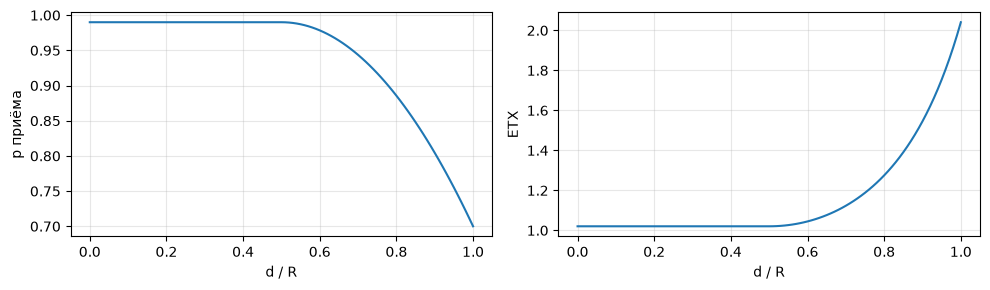

In [6]:
@dataclass
class ChannelConfig:
    """⚙️ Канал."""
    p_max: float = 0.99      # вероятность приёма вблизи
    p_min: float = 0.70      # вероятность приёма на границе R
    d0_frac: float = 0.5     # до какой доли R качество максимально


def link_pdr(d, R, ch: ChannelConfig) -> float:
    x = d / R
    if x <= ch.d0_frac:
        return ch.p_max
    if x >= 1:
        return ch.p_min
    f = (x - ch.d0_frac) / (1 - ch.d0_frac)
    return ch.p_max - (ch.p_max - ch.p_min) * f * f


def etx(d, R, ch: ChannelConfig) -> float:
    p = link_pdr(d, R, ch)
    return 1.0 / (p * p)


# Как качество зависит от расстояния
_ch = ChannelConfig()
_x = [i / 100 for i in range(0, 101)]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(_x, [link_pdr(x, 1, _ch) for x in _x]); ax[0].set_xlabel("d / R"); ax[0].set_ylabel("p приёма")
ax[1].plot(_x, [etx(x, 1, _ch) for x in _x]); ax[1].set_xlabel("d / R"); ax[1].set_ylabel("ETX")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Методы маршрутизации

| Метод | Ключ | Какую информацию использует | Как передаёт |
|---|---|---|---|
| Затопление (Flooding) | `flooding` | Только свой кэш ID и HopLimit в заголовке | Широковещательно, без ACK, со случайной задержкой перед ретрансляцией |
| Дейкстра — эталон | `dijkstra` | Полная карта сети в момент отправки (оракул) | Адресно по маршруту, ACK и повторы на каждом переходе. **HopLimit не учитывает** |
| DP с HopLimit | `dp_hoplimit` | Полная карта сети в момент отправки (оракул) | Как Дейкстра, но путь не длиннее HopLimit. Если такого пути нет, отказ сразу у источника: «недостаточный HopLimit» или «получатель недостижим» |

Стоимость ребра (допущения 3 и 4): c(u, v) = (ToA кадра данных + t_rx_proc + t_tx_prep) · ETX(u, v).

Динамическое программирование по числу переходов: D₀(S) = 0; D_h(v) = min(D_{h−1}(v), min по (u, v) ∈ E [D_{h−1}(u) + c(u, v)]), h = 1…H. Сложность O(H·|E|).

**HopLimit** — максимум передач на пакет. Источник передаёт с `hop_limit = H`, каждый ретранслятор уменьшает его на 1 и пересылает, только если значение больше 1. Поэтому путь из k переходов допустим при k ≤ H.

Маршрут оракульных методов вычисляется у источника в момент отправки. Если узел маршрута пропал или ушёл, пакет теряется после `max_retries` повторов. Это честная цена устаревшего маршрута.

In [7]:
INF = float("inf")


def dijkstra(g, s, t):
    """g: {u: [(v, cost), ...]}. Возвращает (путь, стоимость) или (None, inf)."""
    dist, prev, done = {s: 0.0}, {}, set()
    pq = [(0.0, s)]
    while pq:
        du, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u)
        if u == t:
            break
        for v, c in g.get(u, []):
            nd = du + c
            if nd < dist.get(v, INF):
                dist[v], prev[v] = nd, u
                heapq.heappush(pq, (nd, v))
    if t not in done:
        return None, INF
    path = [t]
    while path[-1] != s:
        path.append(prev[path[-1]])
    return path[::-1], dist[t]


def dp_hoplimit(g, s, t, H):
    """Кратчайший путь не длиннее H переходов.
    Возвращает (путь, стоимость, причина отказа или None)."""
    STAY = "stay"
    D, P = [{s: 0.0}], [{}]
    for _ in range(H):
        prev_layer = D[-1]
        cur = dict(prev_layer)
        par = {v: STAY for v in cur}
        for u, du in prev_layer.items():
            for v, c in g.get(u, []):
                if du + c < cur.get(v, INF):
                    cur[v], par[v] = du + c, u
        D.append(cur); P.append(par)
    if t not in D[H]:
        reachable, _ = dijkstra(g, s, t)
        return None, INF, ("hoplimit_insufficient" if reachable else "unreachable")
    path, h, v = [t], H, t
    while v != s:
        pv = P[h][v]
        h -= 1
        if pv == STAY:
            continue
        path.append(pv)
        v = pv
    return path[::-1], D[H][t], None

**Проверка на примере из программы интенсива.** Граф S, A, B, C, D, E, T; ожидаемые значения: H = 1 → нет пути; H = 2 → 5,0 (S→D→T); H = 3 → 4,3 (S→A→E→T); H ≥ 4 → 4,0 (S→A→B→C→T).

In [8]:
_edges = [("S","A",1.0),("A","B",1.0),("B","C",1.0),("C","T",1.0),
          ("A","E",1.5),("E","T",1.8),("S","D",2.5),("D","T",2.5)]
_g = {}
for u, v, c in _edges:
    _g.setdefault(u, []).append((v, c)); _g.setdefault(v, []).append((u, c))

rows = []
for H in range(1, 6):
    p, c, why = dp_hoplimit(_g, "S", "T", H)
    rows.append({"HopLimit": H, "D_H(T)": round(c, 2) if p else "∞",
                 "путь": " → ".join(p) if p else "—", "причина": why or ""})
p, c = dijkstra(_g, "S", "T")
print("Дейкстра:", " → ".join(p), round(c, 2))
assert [r["D_H(T)"] for r in rows] == ["∞", 5.0, 4.3, 4.0, 4.0]
pd.DataFrame(rows)

Дейкстра: S → A → B → C → T 4.0


,HopLimit,D_H(T),путь,причина
0,1,∞,—,hoplimit_insufficient
1,2,5.0,S → D → T,
2,3,4.3,S → A → E → T,
3,4,4.0,S → A → B → C → T,
4,5,4.0,S → A → B → C → T,


### 4.1. AODV ⚙️

**Идея.** Узлы не держат карту сети и ищут маршрут только тогда, когда есть что отправить. Каждый узел помнит только следующего соседа на пути к каждому получателю.

| Шаг | Кадр | Что происходит |
|---|---|---|
| Поиск | **RREQ** (широковещательно) | Источник рассылает запрос «кто знает путь к D?». Соседи пересылают его дальше, как при затоплении. Каждый узел запоминает, от кого пришёл запрос: это обратный маршрут к источнику |
| Ответ | **RREP** (адресно, с ACK) | Получатель или узел со свежим маршрутом к D отвечает по обратной цепочке. Каждый узел на пути записывает: «к D — через этого соседа» |
| Передача | DATA (адресно, с ACK) | Пакеты идут по таблицам «следующий сосед». Пока маршрут не найден, они ждут в буфере |
| Обрыв | **RERR** (широковещательно) | Сосед не подтвердил кадр после всех повторов: маршруты через него помечаются недействительными, а соседи, которые слали через нас, получают сообщение об ошибке |
| Устаревание | — | Маршрут, которым не пользовались `ACTIVE_ROUTE_TIMEOUT`, стирается |

**Номера последовательности.** У каждого узла есть счётчик. Маршрут с большим номером свежее, при равном номере выигрывает более короткий. Так AODV отличает новые сведения от устаревших и не образует петель.

**Поиск расширяющимся кольцом.** Сначала RREQ рассылается с TTL = 1, потом 3, 5, 7. Если получатель близко, поиск не затапливает всю сеть.

**HELLO.** По RFC узел на активном маршруте раз в секунду сообщает соседям, что он жив. В нашей модели есть подтверждения канального уровня (ACK), поэтому обрыв виден и без HELLO. Вариант с HELLO проверен отдельно.

**Что пересчитано под LoRa.** В RFC `NODE_TRAVERSAL_TIME` = 40 мс, что соответствует Wi-Fi. Кадр LoRa SF7 летит 50–70 мс, плюс подтверждение и задержки, поэтому здесь взято 0,4 с. Из него по формулам RFC получаются все тайм-ауты поиска.

**Варианты** (`AODV_PRESETS`, имя варианта = имя метода в `run_matrix`):

| Ключ | Что это |
|---|---|
| `aodv_rfc` | RFC 3561 как есть |
| `aodv_rfc_hello` | RFC + HELLO раз в секунду |
| `aodv_lora` | RFC + 4 доработки под LoRa. Каждая проверена в разделе 10.4 |

**Доработки `aodv_lora`**

| Доработка | Параметр | Зачем |
|---|---|---|
| Локальная починка | `local_repair` | При обрыве узел не теряет пакет, а держит его и сам ищет новый путь к получателю. В RFC это необязательная опция, по умолчанию пакет теряется |
| Повторы с нарастающей паузой и доверие к недавно слышанному соседу | `retry_backoff_s`, `extra_retries_if_heard` | На LoRa большинство «обрывов» ложные: сосед рядом, но подтверждение утонуло в коллизии с волной RREQ (раздел 10.3). Повторы разносятся по времени (0,2 → 0,4 → 0,8 с). Если соседа слышали в последние 3 с, даётся ещё 3 попытки |
| Маршрут живёт 10 с | `active_route_timeout_s` | В RFC 3 с. При пакете раз в несколько секунд маршрут успевает умереть, и каждый пакет запускает новое затопление |
| Срок доставки 20 с | `deadline_s` | Пакет старше 20 с уже бесполезен по требованиям. Его выбрасывают из очередей, чтобы не тратить эфир |

In [9]:
@dataclass
class AodvConfig:
    """⚙️ Параметры AODV (RFC 3561). Времена пересчитаны под LoRa."""
    # Поиск маршрута (RREQ / RREP)
    node_traversal_s: float = 0.4          # NODE_TRAVERSAL_TIME: оценка времени на переход (RFC: 40 мс для Wi-Fi)
    expanding_ring: bool = True            # поиск расширяющимся кольцом: TTL_START, +TTL_INCREMENT … TTL_THRESHOLD
    ttl_start: int = 1
    ttl_increment: int = 2
    ttl_threshold: int = 7
    timeout_buffer: int = 2
    ring_from_known_hops: bool = False     # RFC 6.4: кольцо начинается с известного числа переходов + TTL_INCREMENT
    rreq_retries: int = 2                  # RREQ_RETRIES: повторов поиска с полным TTL
    rreq_backoff: bool = True              # двоичная экспоненциальная задержка между повторами
    intermediate_reply: bool = True        # узел со свежим маршрутом отвечает на RREQ сам
    # Маршруты
    active_route_timeout_s: float = 3.0    # ACTIVE_ROUTE_TIMEOUT: сколько живёт неиспользуемый маршрут
    metric: str = "hops"                   # "hops" (RFC) | "etx" — стоимость с учётом качества каналов
    etx_delay_s: float = 0.0               # доп. задержка ретрансляции RREQ на единицу (ETX − 1) входящего канала
    rreq_suppress_dups: Optional[int] = None   # не ретранслировать RREQ, если за время ожидания услышано столько копий
    rreq_jitter_s: Optional[tuple] = None  # случайная задержка ретрансляции RREQ (None — как flood_jitter_s узла)
    rrep_delay_s: float = 0.0              # RREP отправляется с задержкой: волна RREQ успевает утихнуть,
                                           # а получатель за это время выбирает лучшую из копий RREQ
    flush_gap_s: float = 0.0               # интервал между пакетами, дождавшимися маршрута (0 — пачкой, как в RFC)
    # Обрыв канала
    local_repair: bool = False             # узел с оборванным каналом сам ищет новый путь, а не теряет пакет
    retry_backoff_s: Optional[float] = None    # пауза перед повтором растёт: b, 2b, 4b… (None — как у всех методов)
    extra_retries_if_heard: int = 0        # доп. повторы, если соседа недавно слышали: скорее коллизия, чем уход
    heard_window_s: float = 3.0
    # Гибрид (см. mesh_routing_hybrid.ipynb): «храни и неси» и первый пакет внутри RREQ
    carry: bool = False                    # поиск не нашёл путь — пакеты не теряются, а ждут у узла до срока
    carry_new_neighbor_s: float = 10.0     # услышали соседа, которого не было столько секунд, — ищем путь заново
    carry_min_gap_s: float = 2.0           # не чаще одного поиска к одному получателю за это время
    carry_poll_s: Optional[float] = None   # дополнительно повторять поиск раз в столько секунд (None — нет)
    piggyback: bool = False                # первый ждущий пакет едет внутри RREQ вместе с поиском
    # HELLO
    hello_interval_s: Optional[float] = None   # None — без HELLO, обрыв определяется по отсутствию ACK
    allowed_hello_loss: int = 2
    # Память и сроки
    pending_capacity: int = 8              # буфер пакетов, ждущих маршрут
    rreq_cache_capacity: int = 64          # кэш (источник, ID) виденных RREQ
    route_table_capacity: int = 32         # таблица маршрутов, записей
    deadline_s: Optional[float] = None     # пакеты старше этого выбрасываются из очередей (None — нет)
    seq_flash_block: int = 1024            # номер последовательности резервируется в ПЗУ блоками
    # Размеры служебных кадров, байт (сверх общего заголовка header_bytes)
    rreq_bytes: int = 16                   # rreq_id 2, orig 2, orig_seq 4, dst 2, dst_seq 4, hops+flags 1, cost 1
    rrep_bytes: int = 12                   # dst 2, dst_seq 4, orig 2, hops 1, cost 1, lifetime 2
    rerr_bytes_base: int = 1
    rerr_bytes_per_dst: int = 6
    hello_bytes: int = 12


# ⚙️ Готовые варианты. Ключ используется как имя метода в run_matrix
AODV_PRESETS = {
    # RFC 3561 как есть; меняется только NODE_TRAVERSAL_TIME — под медленный эфир LoRa
    "aodv_rfc": AodvConfig(),
    # RFC + HELLO раз в секунду: так AODV определяет соседей без подтверждений канального уровня
    "aodv_rfc_hello": AodvConfig(hello_interval_s=1.0),
    # Адаптация под LoRa и подвижную сеть: 4 доработки, каждая значимо помогает (раздел 10.4)
    "aodv_lora": AodvConfig(local_repair=True,                            # пакет ждёт новый путь у узла обрыва
                            retry_backoff_s=0.2, extra_retries_if_heard=3,   # не путать коллизию с уходом соседа
                            active_route_timeout_s=10.0,                  # маршрут живёт дольше, чем в RFC
                            deadline_s=20.0),                             # не тратить эфир на опоздавшие пакеты
}

## 5. Топологии ⚙️

Все расстояния в метрах. По умолчанию R = 600 м (ориентир для SF7 в застройке). Для геометрических топологий канал определяется расстоянием, для явных (доска, дерево) — списком рёбер.

### Стационарные

| Ключ | Узлов | Описание | Что проверяет |
|---|---|---|---|
| `board6` | 6 | Граф с доски: рёбра 1–2, 2–3, 2–5, 5–6, 6–3, 1–4, 2–4, 3–4; поток 1 → 6 | Три равных по числу переходов пути с разным качеством каналов; отказ узла 2 |
| `line10` | 10 | Линия, шаг 0,8R; поток 0 → 6 (6 переходов) | Единственный путь, HopLimit, «недостижим» против «нет допустимого пути». Поток 0 → 9 требует 9 переходов и при HopLimit = 7 недоставим |
| `tree15` | 15 | Бинарное дерево глубины 4 | Лишние пересылки листьев, точки сочленения |
| `ring12` | 12 | Кольцо, соседи на 0,8R | Две дуги, обход обрыва |
| `grid4x4` | 16 | Решётка 4 × 4, шаг 0,8R | Много равных путей, широковещательный шторм, коллизии |
| `mesh30` | 30 | Случайные точки в квадрате 2500 × 2500 м, перегенерация до связности | Качество каналов против числа переходов |

### Подвижные (Random Waypoint)

Узел выбирает случайную точку, идёт к ней со случайной скоростью из диапазона, делает паузу и выбирает следующую.

| Ключ | Узлов | Скорость | Пауза | Пример |
|---|---|---|---|---|
| `rwp30_walk` | 30 | 0,5–1,5 м/с | 0–60 с | Пешеходы, поисковый отряд |
| `rwp30_vehicle` | 30 | 8–15 м/с | 0–10 с | Колонна техники |
| `rwp30_drone` | 30 | 15–25 м/с | 0–5 с | Группа дронов |

**Динамика в обоих вариантах.** Любой топологии можно задать пропадание и появление узлов (раздел 6). Без динамики стационарная сеть не меняется вовсе, а подвижная меняется только из-за движения.

Чтобы добавить свою топологию, напишите функцию `rng → Topology` и добавьте её в словарь `TOPOLOGIES`.

In [10]:
R_DEFAULT = 600.0


class Topology:
    kind = "static"

    def __init__(self, name, nodes, R):
        self.name, self.nodes, self.R = name, list(nodes), R

    def positions(self, t):
        raise NotImplementedError

    def links(self, t, alive):
        """{узел: [(сосед, расстояние), ...]} среди живых узлов в момент t."""
        raise NotImplementedError


class GeometricTopology(Topology):
    """Канал есть, если расстояние ≤ R."""

    def __init__(self, name, pos, R):
        super().__init__(name, pos.keys(), R)
        self.pos = dict(pos)

    def positions(self, t):
        return self.pos

    def links(self, t, alive):
        P = self.positions(t)
        ids = [n for n in self.nodes if n in alive]
        out = {n: [] for n in ids}
        for i, a in enumerate(ids):
            for b in ids[i + 1:]:
                d = math.dist(P[a], P[b])
                if d <= self.R:
                    out[a].append((b, d)); out[b].append((a, d))
        return out


class ExplicitTopology(Topology):
    """Явный список рёбер; координаты нужны для расстояний и рисунка."""

    def __init__(self, name, pos, edges, R):
        super().__init__(name, pos.keys(), R)
        self.pos, self.edges = dict(pos), list(edges)

    def positions(self, t):
        return self.pos

    def links(self, t, alive):
        out = {n: [] for n in self.nodes if n in alive}
        for a, b in self.edges:
            if a in alive and b in alive:
                d = math.dist(self.pos[a], self.pos[b])
                out[a].append((b, d)); out[b].append((a, d))
        return out


class RandomWaypointTopology(GeometricTopology):
    """Подвижная сеть: Random Waypoint в квадрате area × area."""
    kind = "mobile"

    def __init__(self, name, n, area, R, v_range, pause_range, sim_time, rng):
        self.area, self.v_range, self.pause_range = area, v_range, pause_range
        start = {i: (rng.uniform(0, area), rng.uniform(0, area)) for i in range(n)}
        super().__init__(name, start, R)
        self.legs = {}
        for i in range(n):
            t, p, legs = 0.0, start[i], []
            while t < sim_time:
                q = (rng.uniform(0, area), rng.uniform(0, area))
                v = rng.uniform(*v_range)
                dt = math.dist(p, q) / v
                legs.append((t, t + dt, p, q)); t += dt
                pause = rng.uniform(*pause_range)
                legs.append((t, t + pause, q, q)); t += pause
                p = q
            self.legs[i] = (legs, [lg[0] for lg in legs])
        self._cache_t, self._cache = None, None

    def positions(self, t):
        if t == self._cache_t:
            return self._cache
        out = {}
        for i, (legs, starts) in self.legs.items():
            k = max(bisect.bisect_right(starts, t) - 1, 0)
            t0, t1, p, q = legs[k]
            f = 0.0 if t1 <= t0 else min(max((t - t0) / (t1 - t0), 0.0), 1.0)
            out[i] = (p[0] + (q[0] - p[0]) * f, p[1] + (q[1] - p[1]) * f)
        self._cache_t, self._cache = t, out
        return out


def _connected(topo):
    L = topo.links(0.0, set(topo.nodes))
    seen, stack = {topo.nodes[0]}, [topo.nodes[0]]
    while stack:
        for v, _ in L[stack.pop()]:
            if v not in seen:
                seen.add(v); stack.append(v)
    return len(seen) == len(topo.nodes)


# Конструкторы
def topo_board6(rng=None, R=750.0):
    pos = {1: (0, 0), 2: (400, 80), 3: (800, 160), 4: (400, -400), 5: (400, 600), 6: (800, 600)}
    edges = [(1, 2), (2, 3), (2, 5), (5, 6), (6, 3), (1, 4), (2, 4), (3, 4)]
    return ExplicitTopology("board6", pos, edges, R)

def topo_line(rng=None, n=10, R=R_DEFAULT, step=0.8):
    return GeometricTopology(f"line{n}", {i: (i * step * R, 0.0) for i in range(n)}, R)

def topo_ring(rng=None, n=12, R=R_DEFAULT, step=0.8):
    r = step * R / (2 * math.sin(math.pi / n))
    pos = {i: (r * math.cos(2 * math.pi * i / n), r * math.sin(2 * math.pi * i / n)) for i in range(n)}
    return GeometricTopology(f"ring{n}", pos, R)

def topo_grid(rng=None, rows=4, cols=4, R=R_DEFAULT, step=0.8):
    pos = {r * cols + c: (c * step * R, r * step * R) for r in range(rows) for c in range(cols)}
    return GeometricTopology(f"grid{rows}x{cols}", pos, R)

def topo_tree(rng=None, depth=4, R=R_DEFAULT):
    n = 2 ** depth - 1
    pos, edges = {}, []
    for i in range(n):
        lvl = int(math.log2(i + 1)); k = i + 1 - 2 ** lvl
        pos[i] = ((k + 0.5) * 4 * R / 2 ** lvl, -lvl * 0.6 * R)
        if i > 0:
            edges.append(((i - 1) // 2, i))
    return ExplicitTopology(f"tree{n}", pos, edges, R)

def topo_random_mesh(rng, n=30, area=2500.0, R=R_DEFAULT):
    for _ in range(1000):
        pos = {i: (rng.uniform(0, area), rng.uniform(0, area)) for i in range(n)}
        topo = GeometricTopology(f"mesh{n}", pos, R)
        if _connected(topo):
            return topo
    raise RuntimeError("не удалось сгенерировать связную сеть — увеличьте R или плотность")

def topo_rwp(rng, n=30, area=2500.0, R=R_DEFAULT, v_range=(0.5, 1.5), pause_range=(0, 60),
             sim_time=600.0, name="rwp"):
    return RandomWaypointTopology(name, n, area, R, v_range, pause_range, sim_time, rng)


# ⚙️ Каталог топологий: ключ -> (конструктор, поток по умолчанию или None = случайные пары)
TOPOLOGIES = {
    "board6":        (topo_board6,      [(1, 6)]),
    "line10":        (topo_line,        [(0, 6)]),
    "tree15":        (topo_tree,        [(7, 14)]),
    "ring12":        (topo_ring,        [(0, 6)]),
    "grid4x4":       (topo_grid,        [(0, 15)]),
    "mesh30":        (topo_random_mesh, None),
    "rwp30_walk":    (lambda rng, sim_time=600.0: topo_rwp(rng, v_range=(0.5, 1.5), pause_range=(0, 60),
                                                           sim_time=sim_time, name="rwp30_walk"), None),
    "rwp30_vehicle": (lambda rng, sim_time=600.0: topo_rwp(rng, v_range=(8, 15), pause_range=(0, 10),
                                                           sim_time=sim_time, name="rwp30_vehicle"), None),
    "rwp30_drone":   (lambda rng, sim_time=600.0: topo_rwp(rng, v_range=(15, 25), pause_range=(0, 5),
                                                           sim_time=sim_time, name="rwp30_drone"), None),
}

def build_topology(key, rng, sim_time, **kw):
    factory, _ = TOPOLOGIES[key]
    try:
        return factory(rng, sim_time=sim_time, **kw)
    except TypeError:
        return factory(rng, **kw)

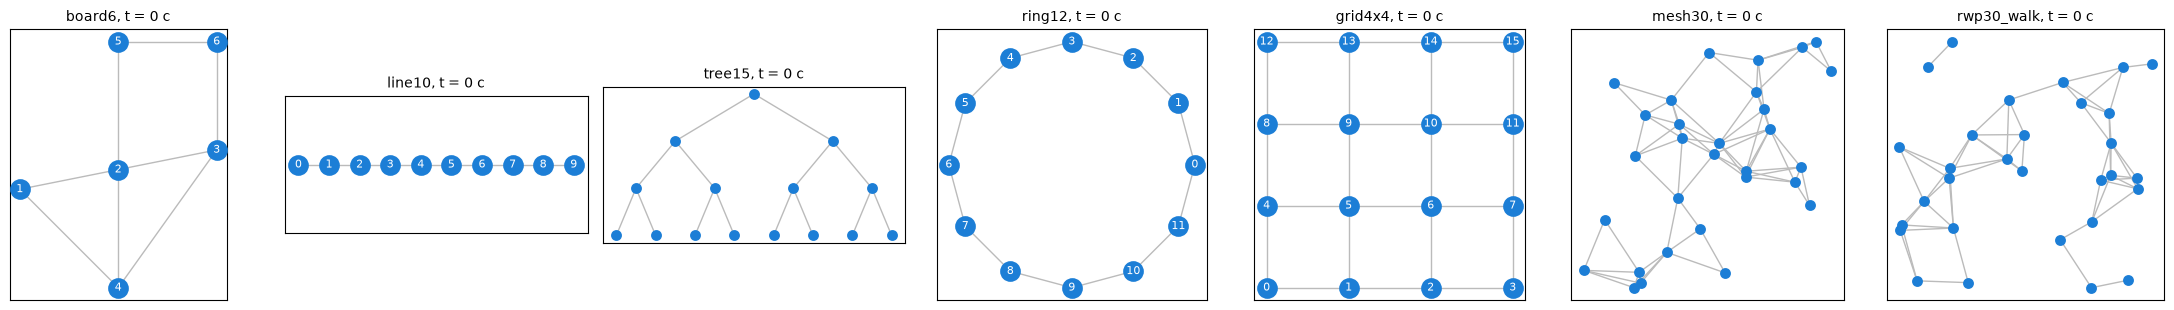

In [11]:
def draw_topology(topo, t=0.0, alive=None, path=None, ax=None, title=None, labels=True):
    alive = set(topo.nodes) if alive is None else alive
    P = topo.positions(t)
    L = topo.links(t, alive)
    ax = ax or plt.gca()
    for a, lst in L.items():
        for b, d in lst:
            if a < b:
                ax.plot([P[a][0], P[b][0]], [P[a][1], P[b][1]], color="#bbb", lw=1, zorder=1)
    if path:
        for a, b in zip(path, path[1:]):
            ax.plot([P[a][0], P[b][0]], [P[a][1], P[b][1]], color="#e8590c", lw=3, zorder=2)
    for n in topo.nodes:
        on = n in alive
        ax.scatter(*P[n], s=180 if labels else 40, zorder=3,
                   color="#1c7ed6" if on else "white", edgecolor="#1c7ed6" if on else "#e03131", lw=1.5)
        if not on:
            ax.scatter(*P[n], marker="x", color="#e03131", s=80, zorder=4)
        if labels:
            ax.text(*P[n], str(n), ha="center", va="center", fontsize=8,
                    color="white" if on else "#e03131", zorder=5)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    xs, ys = [p[0] for p in P.values()], [p[1] for p in P.values()]
    span = max(max(xs) - min(xs), max(ys) - min(ys))
    if max(ys) - min(ys) < 0.2 * span:                # вырожденная (линейная) раскладка
        cy = (max(ys) + min(ys)) / 2
        ax.set_ylim(cy - 0.25 * span, cy + 0.25 * span)
    ax.set_title(title or f"{topo.name}, t = {t:.0f} с", fontsize=10)
    return ax

_keys = ["board6", "line10", "tree15", "ring12", "grid4x4", "mesh30", "rwp30_walk"]
fig, axes = plt.subplots(1, len(_keys), figsize=(3.2 * len(_keys), 3.2))
for ax, k in zip(axes, _keys):
    draw_topology(build_topology(k, random.Random(1), 600.0), ax=ax, labels=k in ("board6", "line10", "ring12", "grid4x4"))
plt.tight_layout(); plt.show()

### 5.1. Наш кейс: 20 подвижных узлов ⚙️

| Ключ | Узлов | Площадь | Скорость | Пауза | Пример |
|---|---|---|---|---|---|
| `rwp20_walk` | 20 | 2000 × 2000 м | 0,5–1,5 м/с | 0–60 с | Пешеходы, поисковый отряд |
| `rwp20_vehicle` | 20 | 2000 × 2000 м | 8–15 м/с | 0–10 с | Техника |
| `rwp20_drone` | 20 | 2000 × 2000 м | 15–25 м/с | 0–5 с | Дроны |

Плотность та же, что у `rwp30_*` из исходного блокнота: в среднем около 5 соседей при R = 600 м. Число узлов и площадь меняются через `topo_kwargs=dict(n=..., area=...)`. Это используется в разделе 10.8.

Важная особенность такой плотности: **сеть время от времени распадается на части**. В 5–7 % случаев пути от источника до получателя в момент отправки просто нет. Такие потери не исправит никакая маршрутизация. Их доля выводится в каждой таблице отдельно.

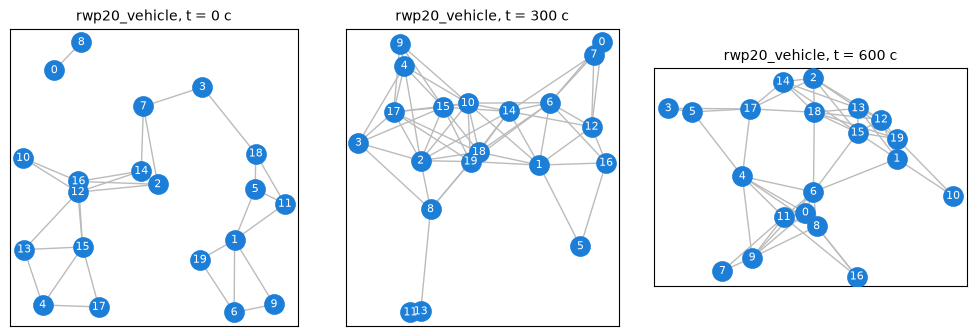

In [12]:
# ⚙️ Наш кейс: до 20 подвижных узлов. Площадь 2000 × 2000 м даёт ту же плотность, что 30 узлов на 2500 × 2500 м
_RWP20 = {"walk": ((0.5, 1.5), (0, 60)), "vehicle": ((8, 15), (0, 10)), "drone": ((15, 25), (0, 5))}
for _k, (_v, _p) in _RWP20.items():
    TOPOLOGIES[f"rwp20_{_k}"] = (
        lambda rng, sim_time=600.0, n=20, area=2000.0, _v=_v, _p=_p, _name=f"rwp20_{_k}":
            topo_rwp(rng, n=n, area=area, v_range=_v, pause_range=_p, sim_time=sim_time, name=_name),
        None)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, t in zip(axes, (0, 300, 600)):
    draw_topology(build_topology("rwp20_vehicle", random.Random(1), 600.0), t=t, ax=ax,
                  title=f"rwp20_vehicle, t = {t} с")
plt.tight_layout(); plt.show()

## 6. Динамика: пропадание и появление узлов ⚙️

Динамика работает одинаково для стационарных и подвижных топологий и складывается из двух частей.

- **Заданные события** `scheduled`: список `(узел, t_выкл, t_вкл)`. Если `t_вкл = None`, узел не возвращается. Пример: `[(2, 100, 300)]` — узел 2 пропадает на 100-й секунде и возвращается на 300-й.
- **Случайные узлы** `random_nodes`:
  - `None` — случайной динамики нет;
  - число k — k случайно выбранных узлов;
  - список — конкретные узлы;
  - `"all"` — все узлы.

  Каждый выбранный узел чередует работу и отсутствие. Длительности распределены экспоненциально со средними `mtbf_s` (работа) и `mttr_s` (отсутствие). Узлы из `protect` случайно не пропадают — обычно это источник и получатель.

Пропавший узел ничего не принимает и не передаёт. Его очередь и кэш стираются, а начатая передача обрывается.

In [13]:
@dataclass
class ChurnConfig:
    """⚙️ Пропадание и появление узлов."""
    scheduled: list = field(default_factory=list)   # [(узел, t_выкл, t_вкл или None)]
    random_nodes: object = None                      # None | k | [узлы] | "all"
    mtbf_s: float = 120.0                            # среднее время работы
    mttr_s: float = 30.0                             # среднее время отсутствия
    protect: tuple = ()                              # не пропадают случайно
    start_s: float = 0.0


def churn_events(ch: ChurnConfig, nodes, sim_time, rng):
    """Список событий (t, узел, "off" | "on")."""
    ev = []
    for n, t_off, t_on in ch.scheduled:
        ev.append((t_off, n, "off"))
        if t_on is not None:
            ev.append((t_on, n, "on"))
    pool = [n for n in nodes if n not in ch.protect]
    if ch.random_nodes is None:
        chosen = []
    elif ch.random_nodes == "all":
        chosen = pool
    elif isinstance(ch.random_nodes, int):
        chosen = rng.sample(pool, min(ch.random_nodes, len(pool)))
    else:
        chosen = [n for n in ch.random_nodes if n in pool]
    for n in chosen:
        t = ch.start_s + rng.expovariate(1 / ch.mtbf_s)
        while t < sim_time:
            ev.append((t, n, "off"))
            t += rng.expovariate(1 / ch.mttr_s)
            if t >= sim_time:
                break
            ev.append((t, n, "on"))
            t += rng.expovariate(1 / ch.mtbf_s)
    return sorted(ev)


def alive_at(events, nodes, t):
    alive = set(nodes)
    for te, n, kind in events:
        if te > t:
            break
        (alive.discard if kind == "off" else alive.add)(n)
    return alive

## 7. Трафик и сценарий ⚙️

**Трафик** — пуассоновский поток пакетов.
- `flows=[(src, dst), ...]` — заданные пары, интенсивность `rate_pps` на каждую пару.
- `flows=None` — случайные пары: для каждого пакета источник и получатель выбираются случайно, `rate_pps` — суммарная интенсивность.

Генерация прекращается за `stop_margin_s` до конца прогона, чтобы последние пакеты успели дойти.

**Сценарий** собирает всё вместе: топологию, HopLimit, размер полезной нагрузки, трафик, динамику, настройки узла, радио и канала. Если `flows` не задан, берётся поток по умолчанию из каталога топологий.

In [14]:
@dataclass
class TrafficConfig:
    flows: Optional[list] = "default"     # "default" | [(src, dst)] | None (случайные пары)
    rate_pps: float = 0.2
    start_s: float = 5.0
    stop_margin_s: float = 30.0


@dataclass
class Scenario:
    """⚙️ Сценарий эксперимента."""
    name: str
    topology: str                          # ключ из TOPOLOGIES
    sim_time_s: float = 600.0
    hop_limit: int = 7
    payload_bytes: int = 20
    traffic: TrafficConfig = field(default_factory=TrafficConfig)
    churn: ChurnConfig = field(default_factory=ChurnConfig)
    node_cfg: NodeConfig = field(default_factory=NodeConfig)
    radio: RadioConfig = field(default_factory=RadioConfig)
    channel: ChannelConfig = field(default_factory=ChannelConfig)
    topo_kwargs: dict = field(default_factory=dict)

## 8. Ядро симулятора

Дискретно-событийная модель: события (генерация пакета, начало и конец передачи, таймаут ACK, пропадание узла, сон) лежат в очереди с приоритетом по времени.

Порядок обработки передачи:
1. **Начало передачи.** Узел переходит в TX. Его текущий приём испорчен (полудуплекс). Каждый живой сосед в радиусе R получает отметку о входящем кадре. Если сосед уже что-то принимает, оба кадра помечаются как коллизия. Если сосед передаёт, спит или выключен, кадр для него потерян.
2. **Конец передачи.** Каждый сосед с неиспорченным кадром принимает его с вероятностью p(d). Кадр ставится в очередь MCU. После обработки (`t_rx_proc_s` плюс ожидание, если MCU занят) вызывается обработчик из раздела 2.
3. **Подготовка передачи.** Перед каждой передачей MCU готовит кадр за `t_tx_prep_s`.

Чтобы встроить свой алгоритм, добавьте ветку `method == "мой_метод"` в `generate` (что делает источник) и в `_on_data` (что делает узел при приёме).

In [15]:
METHODS = ("flooding", "dijkstra", "dp_hoplimit")


class Simulator:
    def __init__(self, sc: Scenario, method: str, seed: int):
        assert method in METHODS or method in AODV_PRESETS, method
        self.sc, self.method, self.seed = sc, method, seed
        self.rng = random.Random(seed)
        self.topo = build_topology(sc.topology, random.Random(seed * 7919 + 1), sc.sim_time_s, **sc.topo_kwargs)
        self.cfg, self.radio, self.ch = sc.node_cfg, sc.radio, sc.channel
        self.nodes = {n: Node(n, self.cfg, self.radio) for n in self.topo.nodes}
        self.t, self._q, self._seq = 0.0, [], itertools.count()
        self._tx_seq, self._pid_seq, self._ack_seq = itertools.count(), itertools.count(), itertools.count()
        self.active_tx, self.packets = {}, {}
        self.stats, self.air = Counter(), Counter()
        self._nbr_t, self._nbr = None, None
        self.data_toa_nominal = lora_toa(self.cfg.header_bytes + sc.payload_bytes
                                         + 4 * self.cfg.route_bytes_per_hop, self.radio)
        self.ack_toa = lora_toa(self.cfg.ack_bytes, self.radio)
        self.churn = churn_events(sc.churn, self.topo.nodes, sc.sim_time_s, random.Random(seed * 104729 + 7))

    # Очередь событий
    def at(self, t, fn, *args):
        heapq.heappush(self._q, (t, next(self._seq), fn, args))

    def run(self):
        self._schedule_traffic()
        for t, n, kind in self.churn:
            self.at(t, self._node_off if kind == "off" else self._node_on, n)
        if self.cfg.sleep_enabled:
            self._schedule_sleep()
        if math.isfinite(self.cfg.battery_j):
            self.at(1.0, self._energy_tick)
        T = self.sc.sim_time_s
        while self._q:
            t, _, fn, args = heapq.heappop(self._q)
            if t > T:
                break
            self.t = t
            fn(*args)
        self.t = T
        for nd in self.nodes.values():
            nd.set_state(nd.state, T)
        return self.summary()

    # Топология
    def alive_set(self):
        return {n for n, nd in self.nodes.items() if nd.alive}

    def _invalidate(self):
        self._nbr_t = None

    def neighbors(self, n):
        if self._nbr_t != self.t:
            self._nbr = self.topo.links(self.t, self.alive_set())
            self._nbr_t = self.t
        return self._nbr.get(n, [])

    def snapshot_graph(self):
        c0 = self.data_toa_nominal + self.cfg.mcu.t_rx_proc_s + self.cfg.mcu.t_tx_prep_s
        return {n: [(m, c0 * etx(d, self.topo.R, self.ch)) for m, d in lst]
                for n, lst in self.topo.links(self.t, self.alive_set()).items()}

    def _reachable(self, s, d):
        """Есть ли сейчас путь s → d (оракул, только для диагностики: потери из-за распада сети)."""
        return dijkstra(self.snapshot_graph(), s, d)[0] is not None

    # Трафик
    def _schedule_traffic(self):
        tr = self.sc.traffic
        flows = TOPOLOGIES[self.sc.topology][1] if tr.flows == "default" else tr.flows
        t_stop = self.sc.sim_time_s - tr.stop_margin_s
        streams = [(s, d) for s, d in flows] if flows else [(None, None)]
        for s, d in streams:
            t = tr.start_s + self.rng.expovariate(tr.rate_pps)
            while t < t_stop:
                # случайная пара выбирается заранее: у всех методов одинаковый трафик при одном seed
                self.at(t, self.generate, *((s, d) if s is not None else self.rng.sample(self.topo.nodes, 2)))
                t += self.rng.expovariate(tr.rate_pps)

    def generate(self, src, dst):
        if src is None:
            src, dst = self.rng.sample(self.topo.nodes, 2)
        node = self.nodes[src]
        if not node.alive:
            self.stats["gen_skipped_src_off"] += 1
            return
        pid = next(self._pid_seq)
        rec = dict(pid=pid, src=src, dst=dst, t_gen=self.t, t_del=None, hops=None,
                   reason=None, copy_reasons=Counter(), path_len=None, reachable=self._reachable(src, dst))
        self.packets[pid] = rec
        H = self.sc.hop_limit
        base = self.cfg.header_bytes + self.sc.payload_bytes
        if self.method == "flooding":
            fr = Frame("DATA", pid, src, dst, H, size=base)
        else:
            g = self.snapshot_graph()
            if self.method == "dijkstra":
                path, _ = dijkstra(g, src, dst)
                why = None if path else "unreachable"
            else:
                path, _, why = dp_hoplimit(g, src, dst, H)
            if path is None:
                rec["reason"] = why                       # отказ у источника, 0 передач
                return
            rec["path_len"] = len(path) - 1
            fr = Frame("DATA", pid, src, dst, H, link_dst=path[1], route=path, idx=0,
                       size=base + len(path) * self.cfg.route_bytes_per_hop)
        node.mark_seen(pid)
        self._enqueue_now(node, fr, node.epoch)

    # Микроконтроллер: задачи выполняются по одной
    def _mcu_task(self, node, dur, fn, *args, force=False):
        """Поставить задачу MCU длительностью dur; fn(*args) — по завершении.
        False, если очередь MCU полна (force=True — для своих передач, всегда принимается)."""
        if not force and node.mcu_pending >= self.cfg.mcu.queue_capacity:
            self.stats["drop_mcu_overflow"] += 1
            return False
        start = max(self.t, node.mcu_busy_until)
        node.mcu_busy_until = start + dur
        node.mcu_active_s += dur
        node.mcu_pending += 1
        if start > self.t:
            self.stats["mcu_waits"] += 1
        self.at(start + dur, self._mcu_done, node, node.epoch, fn, args)
        return True

    def _mcu_done(self, node, epoch, fn, args):
        if node.epoch != epoch:
            return
        node.mcu_pending -= 1
        fn(*args)

    # Очередь и доступ к каналу
    def _enqueue_now(self, node, frame, epoch):
        if node.epoch != epoch or not node.alive:
            return
        if not node.enqueue(frame):
            self.stats["drop_queue_overflow"] += 1
            self._fail(frame.pid, "queue_overflow", definitive=frame.link_dst is not None)
            return
        self._kick(node)

    def _unbusy_kick(self, node, epoch):
        if node.epoch != epoch:
            return
        node.busy = False
        self._kick(node)

    def _kick(self, node):
        if node.busy or not node.queue or not node.alive or not node.awake or node.state != S.RX:
            return
        while node.queue and self._stale(node.queue[0]):  # срок доставки истёк: не тратим эфир
            self._fail(node.queue.popleft().pid, "deadline", definitive=True)
        if not node.queue:
            return
        frame = node.queue[0]
        dur = lora_toa(frame.size, self.radio)
        w = node.dc_wait(self.t, dur)                    # ограничение 3
        if w > 0:
            node.busy = True
            self.stats["duty_cycle_deferrals"] += 1
            self.at(self.t + w, self._unbusy_kick, node, node.epoch)
            return
        if self.cfg.csma and node.incoming and node.csma_attempts < self.cfg.csma_max_attempts:
            node.csma_attempts += 1
            node.busy = True
            self.stats["csma_backoffs"] += 1
            self.at(self.t + self.rng.uniform(*self.cfg.csma_backoff_s), self._unbusy_kick, node, node.epoch)
            return
        node.csma_attempts = 0
        node.queue.popleft()
        node.busy = True
        self._mcu_task(node, self.cfg.mcu.t_tx_prep_s, self._tx_prepared, node, frame, dur, node.epoch, force=True)

    def _tx_prepared(self, node, frame, dur, epoch):
        """MCU подготовил кадр: запускаем передачу, если радио свободно."""
        if node.epoch != epoch or not node.alive:
            return
        if node.state != S.RX:                           # радио занято (ACK) или узел уснул
            node.queue.appendleft(frame)
            node.busy = False
            return                                       # повторный запуск — по концу ACK или пробуждению
        self._start_tx(node, frame, dur)

    # Передача
    def _start_tx(self, node, frame, dur):
        frame = replace(frame, link_src=node.id)
        node.set_state(S.TX, self.t)
        for k in node.incoming:                          # полудуплекс
            node.incoming[k] = "halfduplex"
        txid = next(self._tx_seq)
        rcv = []
        for m, d in self.neighbors(node.id):
            r = self.nodes[m]
            if not r.can_receive:
                st = "not_listening"
            elif r.incoming:                             # коллизия: портятся все
                for k in r.incoming:
                    r.incoming[k] = "collision"
                st = "collision"
            else:
                st = "ok"
            r.incoming[txid] = st
            rcv.append((m, d))
        self.active_tx[txid] = dict(sender=node.id, frame=frame, rcv=rcv, aborted=False)
        node.tx_log.append((self.t, dur)); node.airtime_s += dur; node.tx_count += 1
        self.air[frame.kind] += dur
        self.stats["tx_" + frame.kind] += 1
        self.at(self.t + dur, self._end_tx, txid, node.epoch)

    def _end_tx(self, txid, epoch):
        tx = self.active_tx.pop(txid)
        node, frame = self.nodes[tx["sender"]], tx["frame"]
        if node.epoch == epoch and node.state == S.TX:
            node.set_state(S.RX if node.awake else S.SLEEP, self.t)
        for m, d in tx["rcv"]:
            r = self.nodes[m]
            st = r.incoming.pop(txid, None)
            if st is None:
                continue
            if tx["aborted"]:
                st = "aborted"
            if st != "ok" or not r.can_receive:
                self.stats["rx_fail_" + (st if st != "ok" else "not_listening")] += 1
                continue
            if self.rng.random() > link_pdr(d, self.topo.R, self.ch):
                self.stats["rx_fail_link_loss"] += 1
                continue
            if not self._mcu_task(r, self.cfg.mcu.t_rx_proc_s, self._on_frame, r, frame, r.epoch):
                if frame.kind == "DATA":
                    self._fail(frame.pid, "mcu_overflow", definitive=False)
        if node.epoch != epoch:
            return
        if frame.kind != "ACK" and frame.link_dst is not None:    # адресный кадр: ждём ACK
            node.current = frame
            node.ack_wait_id = next(self._ack_seq)
            m = self.cfg.mcu
            timeout = m.t_rx_proc_s + m.t_tx_prep_s + self.ack_toa + self.cfg.ack_guard_s
            self.at(self.t + timeout, self._ack_timeout, node, epoch, node.ack_wait_id)
        elif frame.kind != "ACK":                        # широковещательный кадр
            node.busy = False
            self._kick(node)
        else:                                            # закончили ACK
            self._kick(node)

    def _send_ack(self, r, data):
        """ACK вне очереди передачи и без CSMA, но с подготовкой на MCU."""
        self._mcu_task(r, self.cfg.mcu.t_tx_prep_s, self._send_ack_now, r, data, r.epoch, force=True)

    def _send_ack_now(self, r, data, epoch):
        if r.epoch != epoch or r.state != S.RX:
            self.stats["ack_skipped_busy_radio"] += 1
            return
        ack = Frame("ACK", data.pid, r.id, data.link_src, 1, link_dst=data.link_src, size=self.cfg.ack_bytes)
        self._start_tx(r, ack, self.ack_toa)

    def _ack_timeout(self, node, epoch, wid):
        if node.epoch != epoch or node.ack_wait_id != wid:
            return
        node.ack_wait_id = None
        fr = node.current
        if node.retries < self._retry_limit(node, fr):
            node.retries += 1
            self.stats["retransmissions"] += 1
            node.queue.appendleft(fr)
            self.at(self.t + self._retry_delay(node), self._unbusy_kick, node, epoch)
        else:
            node.retries, node.current, node.busy = 0, None, False
            self._on_link_fail(node, fr)
            self._kick(node)

    # Приём
    def _on_frame(self, r, frame, epoch):
        if r.epoch != epoch or not r.alive:
            return
        if frame.kind == "ACK":
            cur = r.current
            if (frame.link_dst == r.id and r.ack_wait_id is not None and cur is not None
                    and frame.pid == cur.pid and frame.link_src == cur.link_dst):
                r.ack_wait_id, r.current, r.retries, r.busy = None, None, 0, False
                self._kick(r)
            return
        self._on_data(r, frame)

    def _on_data(self, r, frame):
        if self.method == "flooding":
            if not r.mark_seen(frame.pid):
                self.stats["duplicates"] += 1
                return
            if frame.dst == r.id:
                self._deliver(frame, r)
                return
            if frame.hop_limit > 1:
                fwd = replace(frame, hop_limit=frame.hop_limit - 1, hops=frame.hops + 1)
                self.at(self.t + self.rng.uniform(*self.cfg.flood_jitter_s), self._enqueue_now, r, fwd, r.epoch)
            else:
                self._fail(frame.pid, "hoplimit_exhausted", definitive=False)
            return
        # адресная передача (dijkstra, dp_hoplimit)
        if frame.link_dst != r.id:
            return                                        # чужой кадр
        self._send_ack(r, frame)
        if not r.mark_seen(frame.pid):
            self.stats["duplicates"] += 1
            return
        if frame.dst == r.id:
            self._deliver(frame, r)
            return
        if frame.hop_limit <= 1:
            self._fail(frame.pid, "hoplimit_exceeded", definitive=True)   # эфир потрачен впустую
            return
        k = frame.idx + 1
        fwd = replace(frame, hop_limit=frame.hop_limit - 1, hops=frame.hops + 1,
                      idx=k, link_dst=frame.route[k + 1])
        self._enqueue_now(r, fwd, r.epoch)

    def _deliver(self, frame, r):
        rec = self.packets[frame.pid]
        if rec["t_del"] is None:
            rec["t_del"], rec["hops"] = self.t, frame.hops + 1

    def _fail(self, pid, reason, definitive):
        rec = self.packets.get(pid)
        if rec is None or rec["t_del"] is not None:
            return
        if definitive:
            rec["reason"] = rec["reason"] or reason
        else:
            rec["copy_reasons"][reason] += 1

    # Хуки для методов с собственным состоянием (AODV, раздел 4.1)
    def _stale(self, frame):
        """True — кадр устарел, отбросить из очереди не передавая."""
        return False

    def _retry_limit(self, node, fr):
        return self.cfg.max_retries

    def _retry_delay(self, node):
        return self.rng.uniform(*self.cfg.csma_backoff_s)

    def _on_link_fail(self, node, fr):
        """Адресный кадр не подтверждён после max_retries повторов."""
        self._fail(fr.pid, "link_broken", definitive=True)

    def _on_node_off(self, nd):
        pass

    # Динамика
    def _node_off(self, n):
        nd = self.nodes[n]
        if not nd.alive:
            return
        nd.set_state(S.OFF, self.t)
        nd.epoch += 1
        if nd.current is not None:
            self._fail(nd.current.pid, "node_off", definitive=True)
        for fr in nd.queue:
            self._fail(fr.pid, "node_off", definitive=fr.link_dst is not None)
        self._on_node_off(nd)
        nd.reset_volatile()
        nd.mcu_busy_until = self.t
        for tx in self.active_tx.values():
            if tx["sender"] == n:
                tx["aborted"] = True
        self.stats["node_off_events"] += 1
        self._invalidate()

    def _node_on(self, n):
        nd = self.nodes[n]
        if nd.state != S.OFF:
            return
        nd.set_state(S.RX if nd.awake else S.SLEEP, self.t)
        self._invalidate()

    def _energy_tick(self):
        for n, nd in self.nodes.items():
            if nd.alive:
                nd.set_state(nd.state, self.t)
                if nd.battery_empty(self.t):
                    self._node_off(n)
                    nd.state, nd.t_death = S.DEAD, self.t
                    self.stats["battery_deaths"] += 1
        self.at(self.t + 1.0, self._energy_tick)

    # 3*. Сон
    def _schedule_sleep(self):
        P, f = self.cfg.sleep_period_s, self.cfg.awake_fraction
        for n in self.nodes:
            phase = self.rng.uniform(0, P)
            k = 0
            while True:
                t_sleep = k * P - phase + f * P
                t_wake = (k + 1) * P - phase
                if t_sleep > self.sc.sim_time_s:
                    break
                if t_sleep >= 0:
                    self.at(t_sleep, self._sleep_toggle, n, False)
                if t_wake >= 0:
                    self.at(t_wake, self._sleep_toggle, n, True)
                k += 1

    def _sleep_toggle(self, n, awake):
        nd = self.nodes[n]
        nd.awake = awake
        if not nd.alive:
            return
        if not awake and nd.state == S.RX:
            for k in nd.incoming:
                nd.incoming[k] = "not_listening"
            nd.set_state(S.SLEEP, self.t)
        elif awake and nd.state == S.SLEEP:
            nd.set_state(S.RX, self.t)
            self._kick(nd)

    # Итоги
    def packets_df(self):
        rows = []
        for r in self.packets.values():
            if r["t_del"] is not None:
                outcome = "delivered"
            elif r["reason"]:
                outcome = r["reason"]
            elif r["copy_reasons"]:
                outcome = r["copy_reasons"].most_common(1)[0][0]
            else:
                outcome = "lost_in_channel"
            rows.append(dict(pid=r["pid"], src=r["src"], dst=r["dst"], t_gen=r["t_gen"],
                             latency_s=(r["t_del"] - r["t_gen"]) if r["t_del"] is not None else None,
                             hops=r["hops"], outcome=outcome, reachable=r.get("reachable")))
        return pd.DataFrame(rows)

    def summary(self):
        pk = self.packets_df()
        gen = len(pk)
        dl = pk[pk.outcome == "delivered"] if gen else pk
        air_total = sum(self.air.values())
        T = self.sc.sim_time_s
        out = dict(scenario=self.sc.name, topology=self.sc.topology, kind=self.topo.kind,
                   method=self.method, seed=self.seed, hop_limit=self.sc.hop_limit,
                   generated=gen, delivered=len(dl),
                   pdr=len(dl) / gen if gen else float("nan"),
                   pdr_20s=(dl.latency_s <= DEADLINE_S).sum() / gen if gen else float("nan"),
                   reachable_share=pk.reachable.mean() if gen else float("nan"),
                   latency_mean_s=dl.latency_s.mean() if len(dl) else float("nan"),
                   latency_p95_s=dl.latency_s.quantile(0.95) if len(dl) else float("nan"),
                   latency_max_s=dl.latency_s.max() if len(dl) else float("nan"),
                   airtime_total_s=air_total,
                   airtime_per_delivered_s=air_total / len(dl) if len(dl) else float("nan"),
                   tx_per_delivered=sum(v for k, v in self.stats.items() if k.startswith("tx_")) / len(dl) if len(dl) else float("nan"),
                   overhead_share=(air_total - self.air["DATA"]) / air_total if air_total else 0.0,
                   energy_total_j=sum(n.total_energy_j(T) for n in self.nodes.values()),
                   energy_radio_j=sum(n.energy_j for n in self.nodes.values()),
                   energy_mcu_j=sum(n.mcu_energy_j(T) for n in self.nodes.values()),
                   energy_max_node_j=max(n.total_energy_j(T) for n in self.nodes.values()),
                   mcu_util_max=max(n.mcu_active_s for n in self.nodes.values()) / T,
                   mcu_waits=self.stats["mcu_waits"],
                   max_node_duty=max(n.airtime_s for n in self.nodes.values()) / self.sc.sim_time_s,
                   battery_deaths=self.stats["battery_deaths"],
                   collisions_rx=self.stats["rx_fail_collision"],
                   retransmissions=self.stats["retransmissions"],
                   duty_cycle_deferrals=self.stats["duty_cycle_deferrals"])
        if gen:
            for reason, cnt in pk.outcome.value_counts().items():
                if reason != "delivered":
                    out["fail_" + reason] = cnt
        return out


def simulate(sc: Scenario, method: str, seed: int = 1):
    sim = Simulator(sc, method, seed)
    res = sim.run()
    return res, sim

### 8.1. Реализация AODV

`AodvSimulator` наследует ядро из раздела 8. Канальный уровень общий для всех методов: CSMA, ACK, повторы, лимит эфира, полудуплекс, коллизии. Чтобы встроить AODV, в ядро добавлено несколько хуков; поведение исходных методов не изменилось:

| Хук | Где вызывается | Что делает AODV |
|---|---|---|
| `_on_link_fail` | кадр не подтверждён после всех повторов | помечает маршруты через соседа недействительными, шлёт RERR, чинит или теряет пакет |
| `_retry_limit`, `_retry_delay` | перед повтором | сколько повторов и с какой паузой |
| `_stale` | перед передачей из очереди | выбрасывает пакеты старше срока |
| `_on_node_off` | узел выключился | стирает таблицы (ОЗУ), а граница номеров в ПЗУ остаётся |

Ещё два изменения в ядре: служебные кадры AODV тоже ждут ACK, если они адресные, и учитываются в эфире. И случайные пары «источник → получатель» теперь выбираются заранее, чтобы при одном `seed` все методы получали **одинаковый трафик**.

**Память узла** (`AodvState`, стирается при выключении):
- таблица маршрутов: получатель → следующий сосед, число переходов, номер последовательности, срок жизни, список соседей-предшественников;
- кэш виденных RREQ;
- буфер пакетов, ждущих маршрут;
- время последнего кадра от каждого соседа.

**ПЗУ.** RFC требует, чтобы номер последовательности не убывал и после перезагрузки. Если писать номер в ПЗУ при каждом изменении, это ~10 млн перезаписей за 5 лет, а допустимо 100 000. Поэтому номер резервируется **блоками**: в ПЗУ пишется только граница блока (`seq_flash_block` = 1024), а после включения узел продолжает с этой границы. Это одна запись на 1024 изменения и одна на каждое включение.

**Повторы.** Повтором (потерялся наш ACK) считается кадр с тем же ID пакета **на том же переходе**. После локальной починки пакет может законно пройти через узел второй раз, по новому пути, и это уже не повтор.

**Что не реализовано из RFC:** gratuitous RREP, ожидание `DELETE_PERIOD` после перезагрузки (его заменяет блочное резервирование номеров), фильтрация «чёрного списка» односторонних каналов (в модели каналы симметричны).

In [16]:
@dataclass
class Route:
    """Запись таблицы маршрутов AODV."""
    nxt: int                       # следующий переход
    hops: int                      # число переходов до получателя
    cost: float                    # сумма ETX каналов (для metric = "etx")
    seq: int                       # номер последовательности получателя: чем больше, тем свежее
    expire: float                  # момент, когда маршрут устареет
    valid: bool = True
    precursors: set = field(default_factory=set)   # соседи, которые шлют через нас данные к этому получателю


class AodvState:
    """Энергозависимая память узла AODV: стирается при выключении."""

    def __init__(self, seq):
        self.seq = seq                     # собственный номер последовательности
        self.rreq_id = 0
        self.routes = {}                   # получатель -> Route
        self.rreq_seen = OrderedDict()     # (источник, rreq_id) -> время
        self.pending = {}                  # получатель -> deque пакетов, ждущих маршрут
        self.n_pending = 0
        self.discovery = {}                # получатель -> {"ttl", "retries", "ring", "token"}
        self.rebroadcast = {}              # (источник, rreq_id) -> {"dups"}: отложенные ретрансляции RREQ
        self.collect = {}                  # (источник, rreq_id) -> лучшая копия RREQ у получателя
        self.last_heard = {}               # сосед -> время последнего услышанного кадра
        self.parked = {}                   # получатель -> True: путь не найден, пакеты ждут (carry)
        self.last_try = {}                 # получатель -> время последнего поиска
        self.riding = {}                   # получатель -> пакет, который едет внутри RREQ (piggyback)


FIVE_YEARS_S = 5 * 365 * 24 * 3600


class AodvSimulator(Simulator):
    """AODV (RFC 3561) поверх модели LoRa. Параметры — AODV_PRESETS[method]."""

    def __init__(self, sc, method, seed):
        super().__init__(sc, method, seed)
        self.ac = AODV_PRESETS[method]
        self._ctrl_seq = itertools.count(1)          # ID служебных кадров отрицательные, чтобы не путать с пакетами
        self.ntt = self.ac.node_traversal_s
        self.net_diam = sc.hop_limit                 # NET_DIAMETER
        self.net_traversal = 2 * self.ntt * self.net_diam
        # ПЗУ: верхняя граница зарезервированных номеров переживает выключение
        self.flash_res = {n: 0 for n in self.nodes}
        self.flash_block_writes, self.flash_boot_writes, self.seq_changes = Counter(), Counter(), Counter()
        self.aodv = {n: AodvState(0) for n in self.nodes}
        for n in self.nodes:
            self._seq_bump(n, 0)
        self.flash_block_writes.clear()              # начальная запись при прошивке не считается
        self.peak = Counter()
        self.discovery_times = []

    def run(self):
        if self.ac.hello_interval_s:
            rng = random.Random(self.seed * 31 + 5)    # отдельный генератор: трафик не сдвигается
            for n in self.nodes:
                self.at(rng.uniform(0, self.ac.hello_interval_s), self._hello, n)
        return super().run()

    # Вспомогательное
    def _cid(self):
        return -next(self._ctrl_seq)

    def _m(self, hops, cost):
        return cost if self.ac.metric == "etx" else hops

    def _link_etx(self, a, b):
        """Качество канала по уровню сигнала, который узел измеряет при приёме."""
        P = self.topo.positions(self.t)
        return etx(min(math.dist(P[a], P[b]), self.topo.R), self.topo.R, self.ch)

    def _route(self, n, dst):
        rt = self.aodv[n].routes.get(dst)
        return rt if rt is not None and rt.valid and rt.expire > self.t else None

    def _seq_bump(self, n, new):
        """Номер последовательности не убывает. В ПЗУ пишется только граница блока."""
        st = self.aodv[n]
        if new > st.seq:
            self.seq_changes[n] += 1
            st.seq = new
        while st.seq >= self.flash_res[n]:
            self.flash_res[n] += self.ac.seq_flash_block
            self.flash_block_writes[n] += 1

    def _too_old(self, fr):
        if self.ac.deadline_s is None or fr.kind != "DATA":
            return False
        return self.t - self.packets[fr.pid]["t_gen"] > self.ac.deadline_s

    _stale = _too_old                                # хук очереди передачи в базовом симуляторе

    def _enqueue_now(self, node, frame, epoch):
        super()._enqueue_now(node, frame, epoch)
        self.peak["queue"] = max(self.peak["queue"], len(node.queue))

    # Таблица маршрутов
    def _update_route(self, n, dst, nxt, hops, cost, seq, life):
        """Правило RFC 3561, 6.2: свежее (больший seq) или при равном seq — короче/дешевле."""
        if dst == n:
            return
        st = self.aodv[n]
        rt = st.routes.get(dst)
        now = self.t
        active = rt is not None and rt.valid and rt.expire > now
        if (rt is None or seq > rt.seq
                or (seq == rt.seq and (not active or self._m(hops, cost) < self._m(rt.hops, rt.cost)))):
            pre = rt.precursors if rt is not None and active and rt.nxt == nxt else set()
            st.routes[dst] = Route(nxt, hops, cost, seq, now + life, True, pre)
            if len(st.routes) > self.ac.route_table_capacity:   # вытесняем устаревшую запись
                victim = min(st.routes, key=lambda d: (st.routes[d].valid and st.routes[d].expire > now,
                                                        st.routes[d].expire))
                del st.routes[victim]
                self.stats["route_evictions"] += 1
            self.peak["routes"] = max(self.peak["routes"], len(st.routes))
            if dst in st.pending:
                self._flush(n, dst)
        elif active and rt.nxt == nxt:
            rt.expire = max(rt.expire, now + life)

    # Источник
    def generate(self, src, dst):
        if src is None:
            src, dst = self.rng.sample(self.topo.nodes, 2)
        node = self.nodes[src]
        if not node.alive:
            self.stats["gen_skipped_src_off"] += 1
            return
        pid = next(self._pid_seq)
        self.packets[pid] = dict(pid=pid, src=src, dst=dst, t_gen=self.t, t_del=None, hops=None, reason=None,
                                 copy_reasons=Counter(), path_len=None, reachable=self._reachable(src, dst))
        fr = Frame("DATA", pid, src, dst, self.sc.hop_limit, size=self.cfg.header_bytes + self.sc.payload_bytes)
        node.mark_seen(pid)
        self._route_or_buffer(node, fr)

    def _route_or_buffer(self, node, fr, ttl=None):
        rt = self._route(node.id, fr.dst)
        if rt:
            self._send_data(node, fr, rt)
        else:
            self._buffer(node, fr, ttl)

    def _send_data(self, node, fr, rt):
        rt.expire = max(rt.expire, self.t + self.ac.active_route_timeout_s)
        self._enqueue_now(node, replace(fr, link_dst=rt.nxt), node.epoch)

    def _buffer(self, node, fr, ttl=None):
        st = self.aodv[node.id]
        if st.n_pending >= self.ac.pending_capacity:
            self.stats["drop_buffer_overflow"] += 1
            self._fail(fr.pid, "buffer_overflow", definitive=True)
            return
        st.pending.setdefault(fr.dst, deque()).append(fr)
        st.n_pending += 1
        self.peak["pending"] = max(self.peak["pending"], st.n_pending)
        if fr.dst not in st.discovery:
            self._start_discovery(node.id, fr.dst, ttl)

    def _flush(self, n, dst):
        """Маршрут появился: отправить всё, что ждало."""
        st = self.aodv[n]
        d = st.discovery.pop(dst, None)
        if d is not None:
            self.discovery_times.append(self.t - d["t0"])
        st.parked.pop(dst, None)
        q = list(st.pending.pop(dst, None) or ())
        rid = st.riding.pop(dst, None)
        if rid is not None:                              # не знаем, дошёл ли пакет из RREQ, — шлём и его
            q.insert(0, rid)
            st.n_pending += 1
        for k, fr in enumerate(q):
            st.n_pending -= 1
            if k == 0 or self.ac.flush_gap_s <= 0:
                self._resend(n, fr, self.nodes[n].epoch)
            else:                                     # пачку разносим во времени: меньше коллизий со скрытыми узлами
                self.at(self.t + k * self.ac.flush_gap_s, self._resend, n, fr, self.nodes[n].epoch)

    def _resend(self, n, fr, epoch):
        if self.nodes[n].epoch != epoch:
            self._fail(fr.pid, "node_off", definitive=True)
        elif self._too_old(fr):
            self._fail(fr.pid, "deadline", definitive=True)
        else:
            self._route_or_buffer(self.nodes[n], fr, ttl=fr.hop_limit)

    # Поиск маршрута
    def _start_discovery(self, n, dst, ttl0=None):
        ring = self.ac.expanding_ring and ttl0 is None
        ttl = self.ac.ttl_start if ring else min(ttl0 or self.net_diam, self.net_diam)
        old = self.aodv[n].routes.get(dst)
        if ring and self.ac.ring_from_known_hops and old is not None:   # путь когда-то был: сразу на его длину
            ttl = min(old.hops + self.ac.ttl_increment, self.net_diam)
        st = self.aodv[n]
        st.discovery[dst] = dict(ttl=ttl, retries=0, ring=ring, token=0, t0=self.t)
        st.last_try[dst] = self.t
        st.parked.pop(dst, None)
        self.stats["discoveries"] += 1
        self._send_rreq(n, dst)

    def _rreq_mark(self, st, key):
        st.rreq_seen[key] = self.t
        if len(st.rreq_seen) > self.ac.rreq_cache_capacity:
            st.rreq_seen.popitem(last=False)
        self.peak["rreq_cache"] = max(self.peak["rreq_cache"], len(st.rreq_seen))

    def _send_rreq(self, n, dst):
        st, nd = self.aodv[n], self.nodes[n]
        d = st.discovery[dst]
        self._seq_bump(n, st.seq + 1)                 # RFC: перед RREQ свой номер увеличивается
        st.rreq_id += 1
        self._rreq_mark(st, (n, st.rreq_id))
        old = st.routes.get(dst)
        ctrl = dict(rreq_id=st.rreq_id, orig_seq=st.seq, dst_seq=old.seq if old else None, cost=0.0)
        size = self.cfg.header_bytes + self.ac.rreq_bytes
        if self.ac.piggyback:
            rid = self._take_rider(n, dst)
            if rid is not None:
                ctrl["data"] = rid
                size += self.sc.payload_bytes + 4               # полезная нагрузка + ID пакета и источник
                self.stats["piggybacked"] += 1
        fr = Frame("RREQ", self._cid(), n, dst, d["ttl"], size=size, ctrl=ctrl)
        self._enqueue_now(nd, fr, nd.epoch)
        if d["ring"] and d["ttl"] < self.net_diam:
            wait = 2 * self.ntt * (d["ttl"] + self.ac.timeout_buffer)       # RING_TRAVERSAL_TIME
        else:
            wait = self.net_traversal * (2 ** d["retries"] if self.ac.rreq_backoff else 1)
        d["token"] += 1
        self.at(self.t + wait, self._disc_timeout, n, dst, d["token"], nd.epoch)

    def _disc_timeout(self, n, dst, token, epoch):
        if self.nodes[n].epoch != epoch:
            return
        st = self.aodv[n]
        d = st.discovery.get(dst)
        if d is None or d["token"] != token:
            return
        if self._route(n, dst):
            self._flush(n, dst)
            return
        if d["ring"] and d["ttl"] < self.net_diam:
            d["ttl"] += self.ac.ttl_increment
            if d["ttl"] > self.ac.ttl_threshold:
                d["ttl"] = self.net_diam
            d["ttl"] = min(d["ttl"], self.net_diam)
        elif d["retries"] < self.ac.rreq_retries:
            d["retries"] += 1
            self.stats["rreq_retries"] += 1
        else:
            del st.discovery[dst]
            self.stats["discovery_failed"] += 1
            rid = st.riding.pop(dst, None)
            if rid is not None:                          # пакет из RREQ снова ждёт в буфере
                st.pending.setdefault(dst, deque()).appendleft(rid)
                st.n_pending += 1
            if self.ac.carry:
                self._park(n, dst)
                return
            reason = "no_route" if self._reachable(n, dst) else "unreachable"
            for fr in st.pending.pop(dst, ()):
                st.n_pending -= 1
                self._fail(fr.pid, reason, definitive=True)
            return
        self._send_rreq(n, dst)

    # Гибрид: пакет едет в RREQ, «храни и неси»
    def _take_rider(self, n, dst):
        """Пакет, который поедет внутри RREQ: прежний пассажир или первый из буфера."""
        st = self.aodv[n]
        rid = st.riding.get(dst)
        if rid is not None and self._too_old(rid):
            self._fail(st.riding.pop(dst).pid, "deadline", definitive=True)
            rid = None
        if rid is None and st.pending.get(dst):
            rid = st.pending[dst].popleft()
            st.n_pending -= 1
            st.riding[dst] = rid
        return rid

    def _park(self, n, dst):
        """Пути нет: пакеты ждут у узла до своего срока, пока не появится новый сосед."""
        st = self.aodv[n]
        keep = deque()
        for fr in st.pending.get(dst) or ():
            if self._too_old(fr):
                st.n_pending -= 1
                self._fail(fr.pid, "deadline", definitive=True)
            else:
                keep.append(fr)
        if not keep:
            st.pending.pop(dst, None)
            st.parked.pop(dst, None)
            return
        st.pending[dst] = keep
        st.parked[dst] = True
        self.stats["parked"] += 1
        expire = min(self.packets[fr.pid]["t_gen"] for fr in keep) + (self.ac.deadline_s or DEADLINE_S) + 1e-3
        nxt = expire if self.ac.carry_poll_s is None else min(expire, self.t + self.ac.carry_poll_s)
        self.at(max(nxt, self.t + 1e-3), self._carry_check, n, dst, self.nodes[n].epoch)

    def _carry_check(self, n, dst, epoch):
        st = self.aodv[n]
        if self.nodes[n].epoch != epoch or dst not in st.parked or dst in st.discovery:
            return
        if self._route(n, dst):
            self._flush(n, dst)
        elif (self.ac.carry_poll_s is not None
              and self.t - st.last_try.get(dst, -INF) >= self.ac.carry_poll_s):
            self.stats["carry_retries"] += 1
            self._start_discovery(n, dst, self.net_diam)
        else:
            self._park(n, dst)

    def _carry_wake(self, n):
        """Услышали нового соседа: сеть, возможно, снова связна — ищем путь для ждущих пакетов."""
        st = self.aodv[n]
        for dst in list(st.parked):
            if dst not in st.discovery and self.t - st.last_try.get(dst, -INF) >= self.ac.carry_min_gap_s:
                self.stats["carry_wakeups"] += 1
                self._start_discovery(n, dst, self.net_diam)

    # Приём
    def _on_data(self, r, frame):
        st, u = self.aodv[r.id], frame.link_src
        prev = st.last_heard.get(u)
        st.last_heard[u] = self.t
        if st.parked and (prev is None or self.t - prev > self.ac.carry_new_neighbor_s):
            self._carry_wake(r.id)
        k = frame.kind
        if k == "RREQ":
            return self._on_rreq(r, frame, u)
        if k == "RERR":
            return self._on_rerr(r, frame, u)
        if k == "HELLO":
            return self._on_hello(r, frame, u)
        if frame.link_dst != r.id:                    # адресный кадр не нам
            return
        self._send_ack(r, frame)
        # Повтор того же кадра (потерялся наш ACK) отбрасываем. Ключ — пакет и номер перехода: после починки
        # пакет может законно пройти через узел второй раз по новому пути, и это уже не повтор
        if not r.mark_seen((frame.pid, frame.hops)):
            self.stats["duplicates"] += 1
            return
        if k == "RREP":
            self._on_rrep(r, frame, u)
        else:
            self._on_unicast_data(r, frame, u)

    def _rev_life(self, hops):
        return max(self.ac.active_route_timeout_s, 2 * self.net_traversal - 2 * hops * self.ntt)

    def _on_rreq(self, r, frame, u):
        c, orig = frame.ctrl, frame.src
        if orig == r.id:
            return
        st = self.aodv[r.id]
        key = (orig, c["rreq_id"])
        le = self._link_etx(r.id, u)
        cost, hops = c["cost"] + le, frame.hops + 1
        if key in st.rreq_seen:                       # копия уже виденного запроса
            self.stats["rreq_duplicates"] += 1
            col = st.collect.get(key)
            if col is not None and self._m(hops, cost) < self._m(col["hops"], col["cost"]):
                col.update(u=u, hops=hops, cost=cost)
            elif key in st.rebroadcast:
                st.rebroadcast[key]["dups"] += 1
            return
        self._rreq_mark(st, key)
        if r.id == frame.dst and c.get("data") is not None:     # пакет приехал вместе с поиском
            if self.packets[c["data"].pid]["t_del"] is None:
                self.stats["delivered_in_rreq"] += 1
            self._deliver(replace(c["data"], hops=frame.hops), r)
        if r.id == frame.dst and self.ac.rrep_delay_s > 0:  # получатель ждёт другие копии
            st.collect[key] = dict(u=u, hops=hops, cost=cost, seq=c["orig_seq"], dst_seq=c["dst_seq"])
            self.at(self.t + self.ac.rrep_delay_s, self._dst_reply, r, key, orig, r.epoch)
            return
        self._update_route(r.id, orig, u, hops, cost, c["orig_seq"], self._rev_life(hops))   # обратный маршрут
        if r.id == frame.dst:
            self._reply_as_dst(r, orig, c["dst_seq"])
            return
        rt = self._route(r.id, frame.dst)
        if (self.ac.intermediate_reply and rt is not None and rt.nxt != u
                and (c["dst_seq"] is None or rt.seq >= c["dst_seq"])):
            rt.precursors.add(u)
            self.stats["rrep_intermediate"] += 1
            if c.get("data") is not None:              # поиск тут кончается — пакет дальше едет по маршруту
                left = max(c["data"].hop_limit - hops, 1)
                self._route_or_buffer(r, replace(c["data"], hops=hops, hop_limit=left, link_dst=None), ttl=left)
            self.at(self.t + self.ac.rrep_delay_s, self._intermediate_reply, r, frame.dst, orig, r.epoch)
            return
        if frame.hop_limit > 1:
            fwd = replace(frame, hop_limit=frame.hop_limit - 1, hops=hops, ctrl={**c, "cost": cost})
            delay = self.rng.uniform(*(self.ac.rreq_jitter_s or self.cfg.flood_jitter_s)) + self.ac.etx_delay_s * (le - 1)
            st.rebroadcast[key] = {"dups": 0}
            self.at(self.t + delay, self._rreq_fire, r, key, fwd, r.epoch)

    def _rreq_fire(self, r, key, fwd, epoch):
        if r.epoch != epoch:
            return
        rb = self.aodv[r.id].rebroadcast.pop(key, None)
        if rb is None:
            return
        if self.ac.rreq_suppress_dups is not None and rb["dups"] >= self.ac.rreq_suppress_dups:
            self.stats["rreq_suppressed"] += 1
            return
        self._enqueue_now(r, fwd, epoch)

    def _intermediate_reply(self, r, dst, orig, epoch):
        rt = self._route(r.id, dst) if r.epoch == epoch else None
        if rt is not None:
            self._send_rrep(r, dst, orig, rt.hops, rt.cost, rt.seq, rt.expire - self.t)

    def _dst_reply(self, r, key, orig, epoch):
        if r.epoch != epoch:
            return
        col = self.aodv[r.id].collect.pop(key, None)
        if col is None:
            return
        self._update_route(r.id, orig, col["u"], col["hops"], col["cost"], col["seq"], self._rev_life(col["hops"]))
        self._reply_as_dst(r, orig, col["dst_seq"])

    def _reply_as_dst(self, r, orig, req_dst_seq):
        if req_dst_seq is not None:
            self._seq_bump(r.id, req_dst_seq)         # RFC 6.6.1: не меньше запрошенного
        self.stats["rrep_dst"] += 1
        self._send_rrep(r, r.id, orig, 0, 0.0, self.aodv[r.id].seq, 2 * self.ac.active_route_timeout_s)

    def _send_rrep(self, r, dst, orig, hops, cost, dst_seq, life):
        rev = self._route(r.id, orig)
        if rev is None:
            self.stats["rrep_no_reverse"] += 1
            return
        fr = Frame("RREP", self._cid(), dst, orig, self.net_diam, link_dst=rev.nxt, hops=hops,
                   size=self.cfg.header_bytes + self.ac.rrep_bytes, ctrl=dict(dst_seq=dst_seq, cost=cost, life=life))
        self._enqueue_now(r, fr, r.epoch)

    def _on_rrep(self, r, frame, u):
        c = frame.ctrl
        hops, cost = frame.hops + 1, c["cost"] + self._link_etx(r.id, u)
        if frame.dst == r.id:                          # ответ на наш поиск: пакет из RREQ уже доставлен
            self.aodv[r.id].riding.pop(frame.src, None)
        self._update_route(r.id, frame.src, u, hops, cost, c["dst_seq"], c["life"])    # прямой маршрут
        if frame.dst == r.id:
            self.stats["rrep_received"] += 1
            return
        rev = self._route(r.id, frame.dst)
        if rev is None:
            self.stats["rrep_no_reverse"] += 1
            return
        fwd_rt = self._route(r.id, frame.src)
        if fwd_rt is not None:
            fwd_rt.precursors.add(rev.nxt)
        rev.precursors.add(u)
        rev.expire = max(rev.expire, self.t + self.ac.active_route_timeout_s)
        self._enqueue_now(r, replace(frame, link_dst=rev.nxt, hops=hops, ctrl={**c, "cost": cost}), r.epoch)

    def _on_unicast_data(self, r, frame, u):
        if frame.dst == r.id:
            self._deliver(frame, r)
            return
        rs = self._route(r.id, frame.src)              # RFC: использование продлевает и обратный маршрут
        if rs is not None:
            rs.expire = max(rs.expire, self.t + self.ac.active_route_timeout_s)
        if frame.hop_limit <= 1:
            self._fail(frame.pid, "hoplimit_exceeded", definitive=True)
            return
        fwd = replace(frame, hop_limit=frame.hop_limit - 1, hops=frame.hops + 1, link_dst=None)
        rt = self._route(r.id, frame.dst)
        if rt is not None:
            rt.precursors.add(u)
            self._send_data(r, fwd, rt)
            return
        self.stats["data_no_route"] += 1
        if self.ac.local_repair and not self._too_old(fwd):
            self.stats["local_repairs"] += 1
            self._buffer(r, fwd, ttl=fwd.hop_limit)
            return
        old = self.aodv[r.id].routes.get(frame.dst)
        self._send_rerr(r.id, [(frame.dst, old.seq if old else 0)])
        self._fail(frame.pid, "no_route", definitive=True)

    # Обрыв канала
    def _retry_limit(self, node, fr):
        heard = self.aodv[node.id].last_heard.get(fr.link_dst)
        recent = heard is not None and self.t - heard <= self.ac.heard_window_s
        return self.cfg.max_retries + (self.ac.extra_retries_if_heard if recent else 0)

    def _retry_delay(self, node):
        b = self.ac.retry_backoff_s
        if b is None:
            return super()._retry_delay(node)
        return b * 2 ** min(node.retries - 1, 4) * self.rng.uniform(0.5, 1.0)

    def _on_link_fail(self, node, fr):
        """После max_retries повторов без ACK."""
        v = fr.link_dst
        self.stats["link_breaks"] += 1
        self._break_link(node.id, v)
        stuck = [f for f in node.queue if f.link_dst == v and f.kind in ("DATA", "RREP")]
        for f in stuck:                               # кадры в очереди к тому же соседу
            node.queue.remove(f)
        for f in [fr] + stuck:
            if f.kind != "DATA":
                self.stats["rrep_lost_link"] += f.kind == "RREP"
                continue
            if self.ac.local_repair and not self._too_old(f):
                self.stats["local_repairs"] += 1
                self._route_or_buffer(node, replace(f, link_dst=None), ttl=f.hop_limit)
            else:
                self._fail(f.pid, "link_broken", definitive=True)

    def _break_link(self, n, v):
        st = self.aodv[n]
        unreach = []
        for dst, rt in st.routes.items():
            if rt.valid and rt.nxt == v:
                rt.valid, rt.seq, rt.expire = False, rt.seq + 1, self.t
                if rt.precursors:
                    unreach.append((dst, rt.seq))
        st.last_heard.pop(v, None)
        if unreach:
            self._send_rerr(n, unreach)

    def _send_rerr(self, n, unreach):
        nd = self.nodes[n]
        size = self.cfg.header_bytes + self.ac.rerr_bytes_base + self.ac.rerr_bytes_per_dst * len(unreach)
        self.stats["rerr_sent"] += 1
        self._enqueue_now(nd, Frame("RERR", self._cid(), n, -1, 1, size=size, ctrl=dict(unreach=unreach)), nd.epoch)

    def _on_rerr(self, r, frame, u):
        st = self.aodv[r.id]
        prop = []
        for dst, seq in frame.ctrl["unreach"]:
            rt = st.routes.get(dst)
            if rt is not None and rt.valid and rt.nxt == u:
                rt.valid, rt.seq, rt.expire = False, max(rt.seq, seq), self.t
                if rt.precursors:
                    prop.append((dst, rt.seq))
        if prop:
            self._send_rerr(r.id, prop)

    # HELLO
    def _hello(self, n):
        nd, st, a = self.nodes[n], self.aodv[n], self.ac
        if nd.alive:
            lim = self.t - a.allowed_hello_loss * a.hello_interval_s
            for v in [v for v, tl in st.last_heard.items() if tl < lim]:
                if any(rt.valid and rt.nxt == v for rt in st.routes.values()):
                    self.stats["hello_link_breaks"] += 1
                    self._break_link(n, v)
                st.last_heard.pop(v, None)
            if any(rt.valid and rt.expire > self.t for rt in st.routes.values()):   # RFC: только на активном маршруте
                self._enqueue_now(nd, Frame("HELLO", self._cid(), n, -1, 1, size=self.cfg.header_bytes + a.hello_bytes,
                                            ctrl=dict(seq=st.seq)), nd.epoch)
        self.at(self.t + a.hello_interval_s * self.rng.uniform(0.95, 1.05), self._hello, n)

    def _on_hello(self, r, frame, u):
        life = self.ac.allowed_hello_loss * self.ac.hello_interval_s
        self._update_route(r.id, u, u, 1, self._link_etx(r.id, u), frame.ctrl["seq"], life)

    # Выключение: таблицы и буфер стираются, граница номеров в ПЗУ остаётся
    def _on_node_off(self, nd):
        st = self.aodv[nd.id]
        for fr in [f for q in st.pending.values() for f in q] + list(st.riding.values()):
            self._fail(fr.pid, "node_off", definitive=True)
        self.aodv[nd.id] = AodvState(self.flash_res[nd.id])
        before = self.flash_block_writes[nd.id]
        self._seq_bump(nd.id, self.flash_res[nd.id])  # после включения — с новой границы блока
        self.flash_boot_writes[nd.id] += self.flash_block_writes[nd.id] - before
        self.flash_block_writes[nd.id] = before

    # Ресурсы и итоги
    def ram_bytes(self):
        """ОЗУ под структуры маршрутизации при статическом выделении по ёмкостям."""
        a, c = self.ac, self.cfg
        frame_b = c.header_bytes + self.sc.payload_bytes + 8          # кадр + служебные поля в памяти
        return (a.route_table_capacity * 24 + a.rreq_cache_capacity * 8 + a.pending_capacity * frame_b
                + c.queue_capacity * frame_b + c.mcu.queue_capacity * frame_b + c.seen_cache_capacity * 4
                + 2 * len(self.nodes) * 8)                            # отложенные RREQ и последние услышанные соседи

    def summary(self):
        out = super().summary()
        T, air_total = self.sc.sim_time_s, sum(self.air.values())
        for k in ("RREQ", "RREP", "RERR", "HELLO"):
            out["air_share_" + k] = self.air[k] / air_total if air_total else 0.0
        for k in ("discoveries", "discovery_failed", "rrep_intermediate", "rreq_suppressed",
                  "link_breaks", "local_repairs", "rerr_sent", "hello_link_breaks",
                  "piggybacked", "parked", "carry_wakeups", "carry_retries", "delivered_in_rreq"):
            out[k] = self.stats[k]
        out["discovery_time_mean_s"] = (sum(self.discovery_times) / len(self.discovery_times)
                                        if self.discovery_times else float("nan"))
        out["flash_naive_5y"] = max(self.seq_changes[n] for n in self.nodes) / T * FIVE_YEARS_S
        out["flash_writes_5y"] = out["flash_naive_5y"] / self.ac.seq_flash_block   # ожидаемое при записи блоками
        out["flash_boot_writes"] = sum(self.flash_boot_writes.values())
        out["ram_bytes"] = self.ram_bytes()
        for k in ("routes", "pending", "queue", "rreq_cache"):
            out["peak_" + k] = self.peak[k]
        return out


def simulate(sc: Scenario, method: str, seed: int = 1):
    sim = (AodvSimulator if method in AODV_PRESETS else Simulator)(sc, method, seed)
    res = sim.run()
    return res, sim

## 9. Метрики и графики

| Метрика | Смысл |
|---|---|
| `pdr` | Доля доставленных пакетов |
| `latency_mean_s`, `latency_p95_s` | Задержка доставки: средняя и 95-й перцентиль |
| `airtime_per_delivered_s` | Суммарное эфирное время всех узлов на один доставленный пакет — главный показатель расхода эфира |
| `tx_per_delivered` | Передач (DATA + ACK) на доставленный пакет |
| `overhead_share` | Доля служебного трафика (ACK) в эфирном времени |
| `energy_total_j`, `energy_max_node_j` | Энергия (радио + MCU): суммарная и самого нагруженного узла |
| `energy_radio_j`, `energy_mcu_j` | Раздельный расход радио и микроконтроллера |
| `mcu_util_max`, `mcu_waits` | Максимальная загрузка MCU среди узлов; сколько задач ждали освобождения MCU |
| `max_node_duty` | Максимальная доля времени в передаче среди узлов |
| `fail_*` | Причины недоставки: `unreachable`, `hoplimit_insufficient` (отказ у источника), `hoplimit_exceeded` / `hoplimit_exhausted` (эфир потрачен), `link_broken`, `queue_overflow`, `mcu_overflow`, `node_off`, `lost_in_channel` |

### 9.1. Метрики под наши требования

| Метрика | Смысл |
|---|---|
| `pdr_20s` | **Главная.** Доля пакетов, доставленных не позже 20 с. Требование: ≥ 0,9 |
| `reachable_share` | Доля пакетов, для которых в момент отправки путь вообще существовал (оракул). 1 − `reachable_share` — потери из-за распада сети, которые не исправит никакая маршрутизация |
| `latency_max_s` | Наибольшая задержка доставленного пакета |
| `overhead_share` | Доля служебного эфира: ACK и все кадры AODV |
| `air_share_RREQ` / `RREP` / `RERR` / `HELLO` | Доля эфира по типам служебных кадров AODV |
| `discoveries`, `discovery_failed`, `discovery_time_mean_s` | Поиски маршрута: сколько начато, сколько не нашли путь, среднее время поиска |
| `link_breaks`, `local_repairs`, `rerr_sent` | Обрывы канала, локальные починки, отправленные RERR |
| `ram_bytes` | ОЗУ под структуры маршрутизации при статическом выделении по ёмкостям |
| `peak_routes`, `peak_pending`, `peak_queue`, `peak_rreq_cache` | Сколько из выделенного реально занималось |
| `flash_writes_5y` | Ожидаемое число перезаписей ПЗУ за 5 лет при записи номера блоками. Не считая записей при включении: одна на каждое включение (`flash_boot_writes`) |
| `flash_naive_5y` | То же, если писать номер при каждом изменении |
| `fail_*` (новые) | `no_route` — поиск не нашёл путь, хотя он был; `buffer_overflow` — переполнен буфер ожидания; `deadline` — пакет выброшен как опоздавший |

In [17]:
def run_matrix(scenarios, methods=METHODS, seeds=range(1, 6), verbose=True):
    rows = []
    for sc in scenarios:
        for m in methods:
            for s in seeds:
                res, _ = simulate(sc, m, s)
                rows.append(res)
        if verbose:
            print(f"готово: {sc.name}")
    return pd.DataFrame(rows).fillna({c: 0 for c in pd.DataFrame(rows).columns if c.startswith("fail_")})


def aggregate(df, by=("scenario", "method"),
              cols=("pdr", "airtime_per_delivered_s", "latency_mean_s", "tx_per_delivered", "overhead_share", "energy_total_j")):
    """Среднее ± стандартное отклонение по повторам."""
    g = df.groupby(list(by))[list(cols)]
    mean, std = g.mean(), g.std().fillna(0)
    out = mean.copy()
    for c in cols:
        out[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(mean[c], std[c])]
    return out


def plot_compare(df, x="scenario", metrics=("pdr", "airtime_per_delivered_s", "latency_mean_s"), title=""):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 3.6))
    xs = list(dict.fromkeys(df[x]))
    methods = list(dict.fromkeys(df["method"]))
    w = 0.8 / len(methods)
    colors = METHOD_COLORS
    for ax, met in zip(axes, metrics):
        for i, m in enumerate(methods):
            sub = df[df.method == m].groupby(x)[met]
            mean, std = sub.mean().reindex(xs), sub.std().reindex(xs).fillna(0)
            pos = [j + (i - (len(methods) - 1) / 2) * w for j in range(len(xs))]
            ax.bar(pos, mean, w, yerr=std, capsize=3, label=m, color=colors.get(m))
        ax.set_xticks(range(len(xs))); ax.set_xticklabels(xs, rotation=20, ha="right", fontsize=8)
        ax.set_title(met, fontsize=10); ax.grid(axis="y", alpha=.3)
    axes[0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()


def plot_snapshots(sc: Scenario, seed=1, times=(0, 150, 300, 450)):
    sim = Simulator(sc, "flooding", seed)
    fig, axes = plt.subplots(1, len(times), figsize=(3.6 * len(times), 3.6))
    for ax, t in zip(axes, times):
        draw_topology(sim.topo, t=t, alive=alive_at(sim.churn, sim.topo.nodes, t), ax=ax,
                      labels=len(sim.topo.nodes) <= 16)
    plt.tight_layout(); plt.show()

## 10. Гибрид: AODV-LoRa + первый пакет в RREQ + «храни и неси»

**Механизм 1. Первый пакет едет внутри RREQ** (`piggyback`). Когда источнику нужен маршрут, первый ждущий пакет кладётся прямо в запрос RREQ: +24 байта, кадр растёт с 28 до 52 байт. RREQ всё равно затапливает сеть, поэтому пакет доходит до получателя вместе с поиском, ещё до ответа RREP.
- Если запрос дошёл до получателя, тот доставляет пакет и отвечает RREP. Источник понимает, что пакет уже у получателя, и больше его не шлёт.
- Если на запрос ответил промежуточный узел со свежим маршрутом, этот узел сам отправляет пакет дальше по маршруту.
- Если ответа нет, следующий RREQ (следующее кольцо или повтор) снова везёт тот же пакет.

Получается **затопление с повтором до подтверждения**. Пока пути нет, пакет рассылается снова и снова при каждом поиске, а как только приходит RREP, источник переходит на дешёвую адресную передачу. Простое затопление так не умеет: у него нет обратной связи, и повторять приходится вслепую (контрольные методы `flooding_x2` и `flooding_x3`).

**Механизм 2. «Храни и неси»** (`carry`). Если поиск не нашёл путь, пакеты не теряются, а ждут у узла до срока 20 с. Когда узел слышит кадр от соседа, которого не слышал больше 10 с, он ищет путь заново, но не чаще раза в 2 с на получателя. Соседей слушаем по любому их кадру, HELLO не нужен. Это позволило сократить слепые повторы поиска с 2 до 1 и сэкономить эфир.

**Где в коде.** Механизмы реализованы в `AodvSimulator` (раздел 8.1) и включаются параметрами `AodvConfig`:

| Параметр | Значение в `hybrid` | Метод в коде |
|---|---|---|
| `piggyback` | `True` | `_take_rider`, `_on_rreq` |
| `carry` | `True` | `_park`, `_carry_check`, `_carry_wake` |
| `carry_new_neighbor_s`, `carry_min_gap_s` | 10 с, 2 с | `_carry_wake` |
| `rreq_retries` | 1 (в `aodv_lora` — 2) | `_disc_timeout` |
| `ring_from_known_hops` | `False` («быстрый режим», раздел 11.4) | `_start_discovery` |

**Цена в памяти.** На каждого получателя в пути находится не больше одного пакета, и он берётся из того же буфера ожидания. ОЗУ не растёт (раздел 11.8).

In [18]:
# ⚙️ Гибрид и контрольные методы
HYBRID = replace(AODV_PRESETS["aodv_lora"],
                 piggyback=True,          # первый пакет едет внутри RREQ: доставка уже во время поиска
                 carry=True,              # пути нет — пакеты ждут у узла до срока и ищут путь при появлении соседа
                 rreq_retries=1)          # меньше слепых повторов поиска: их заменяет «храни и неси»
AODV_PRESETS["hybrid"] = HYBRID

# Контроль: «а не то же ли это, что затопить пакет несколько раз?»
# Источник повторяет затопление пакета k раз с интервалом gap, не зная, дошёл ли он
FLOOD_REPEAT = {"flooding_x2": (2, 3.0), "flooding_x3": (3, 3.0)}


class FloodRepeatSimulator(Simulator):
    """Затопление с k повторными рассылками каждого пакета от источника."""

    def __init__(self, sc, method, seed):
        super().__init__(sc, "flooding", seed)          # внутри — обычное затопление
        self.label = method
        self.repeats, self.gap = FLOOD_REPEAT[method]

    def summary(self):
        return {**super().summary(), "method": self.label}

    def generate(self, src, dst):
        n_before = len(self.packets)
        super().generate(src, dst)
        if len(self.packets) == n_before:                 # источник выключен — пакета нет
            return
        pid = next(reversed(self.packets))
        node = self.nodes[self.packets[pid]["src"]]
        for k in range(1, self.repeats):
            self.at(self.t + k * self.gap, self._repeat, node, pid, k, node.epoch)

    def _repeat(self, node, pid, k, epoch):
        if node.epoch != epoch or not node.alive:
            return
        rec = self.packets[pid]
        node.mark_seen((pid, k))
        self._enqueue_now(node, Frame("DATA", pid, rec["src"], rec["dst"], self.sc.hop_limit,
                                      size=self.cfg.header_bytes + self.sc.payload_bytes, ctrl={"rep": k}), epoch)

    def _on_data(self, r, frame):
        rep = (frame.ctrl or {}).get("rep", 0)
        if not r.mark_seen(frame.pid if rep == 0 else (frame.pid, rep)):
            self.stats["duplicates"] += 1
            return
        if frame.dst == r.id:
            self._deliver(frame, r)
            return
        if frame.hop_limit > 1:
            fwd = replace(frame, hop_limit=frame.hop_limit - 1, hops=frame.hops + 1)
            self.at(self.t + self.rng.uniform(*self.cfg.flood_jitter_s), self._enqueue_now, r, fwd, r.epoch)
        else:
            self._fail(frame.pid, "hoplimit_exhausted", definitive=False)


def simulate(sc: Scenario, method: str, seed: int = 1):
    if method in FLOOD_REPEAT:
        cls = FloodRepeatSimulator
    elif method in AODV_PRESETS:
        cls = AodvSimulator
    else:
        cls = Simulator
    sim = cls(sc, method, seed)
    return sim.run(), sim


METHOD_COLORS.update({"hybrid": "#2f9e44", "flooding_x2": "#4dabf7", "flooding_x3": "#a5d8ff"})

### Методы для сравнения

| Метод | Что это |
|---|---|
| `flooding` | Затопление |
| `flooding_x3` | Контроль: источник затапливает каждый пакет 3 раза с интервалом 3 с, не зная, дошёл ли он |
| `dijkstra` | Эталон: в момент отправки знает всю карту сети. Если пути нет, пакет теряется |
| `aodv_lora` | AODV с 4 доработками под LoRa (`mesh_routing_aodv.ipynb`) |
| `hybrid` | `aodv_lora` + первый пакет в RREQ + «храни и неси» |

## 11. Эксперименты

Условия те же, что в исследовании AODV:
- 20 узлов на 2000 × 2000 м, R = 600 м, LoRa SF7;
- прогон 600 с, суммарно 0,2 пакета/с;
- трафик `random` (случайные пары) или `sink` (все → узел 0).

Одинаковый `seed` даёт всем методам одинаковые топологию, движение и трафик. Результаты сохраняются в `results/hybrid/`.

In [19]:
# EXP: общие функции экспериментов
import os
from dataclasses import replace as dc_replace

RESULTS_DIR = "results"
RERUN = False          # True — пересчитать все эксперименты заново (≈ 40 мин на одном ядре); False — взять results/*.csv
MAIN_METHODS = ("flooding", "dijkstra", "aodv_rfc", "aodv_lora")
MOBILITY = {"rwp20_walk": "пешеходы", "rwp20_vehicle": "техника", "rwp20_drone": "дроны"}


def make_scenario(topo, pattern="random", rate=0.2, churn=False, sim_time=600.0, n=None, area=None, name=None):
    """Сценарий нашего кейса. pattern: random — случайные пары, sink — все шлют узлу 0 (координатору)."""
    kw = {k: v for k, v in dict(n=n, area=area).items() if v is not None}
    nodes = n or 20
    if pattern == "random":
        tr = TrafficConfig(flows=None, rate_pps=rate)
    elif pattern == "sink":
        tr = TrafficConfig(flows=[(i, 0) for i in range(1, nodes)], rate_pps=rate / (nodes - 1))
    else:
        tr = TrafficConfig(flows="default", rate_pps=rate)
    ch = ChurnConfig(random_nodes="all", mtbf_s=300, mttr_s=30) if churn else ChurnConfig()
    return Scenario(name or topo, topo, sim_time_s=sim_time, traffic=tr, churn=ch, topo_kwargs=kw)


def run_spec(spec):
    """Один прогон. spec: topo, method, seed + параметры make_scenario; aodv={...} — вариант AODV поверх base."""
    if "aodv" in spec:
        AODV_PRESETS[spec["method"]] = dc_replace(AODV_PRESETS[spec.get("base", "aodv_rfc")], **spec["aodv"])
    sc_kw = {k: spec[k] for k in ("pattern", "rate", "churn", "sim_time", "n", "area") if k in spec}
    res, _ = simulate(make_scenario(spec["topo"], **sc_kw), spec["method"], spec["seed"])
    res.update({k: v for k, v in spec.items() if k not in ("aodv", "base")})
    return res


def run_grid(name, specs):
    """Прогоняет список спецификаций или берёт сохранённый результат results/<name>.csv."""
    path = os.path.join(RESULTS_DIR, name + ".csv")
    if not RERUN and os.path.exists(path):
        return pd.read_csv(path)
    df = pd.DataFrame([run_spec(s) for s in specs])
    df = df.fillna({c: 0 for c in df.columns if c.startswith("fail_")})
    os.makedirs(RESULTS_DIR, exist_ok=True)
    df.to_csv(path, index=False)
    return df


def grid(methods, seeds, **axes):
    """Все сочетания: grid(["flooding"], range(1, 6), topo=[...], rate=[...])."""
    return [dict(zip(axes, combo), method=m, seed=s)
            for combo in itertools.product(*axes.values()) for m in methods for s in seeds]


def variants(names_to_overrides, seeds, base="aodv_rfc", **axes):
    """Варианты AODV: {имя: {параметр: значение}} поверх пресета base."""
    out = []
    for name, d in names_to_overrides.items():
        for sp in grid([name], seeds, **axes):
            out.append({**sp, "aodv": dict(d), "base": base})
    return out


def criteria_table(df, by=("topo", "method")):
    """Проверка требований подвижного случая (см. «Постановку»)."""
    g = df.groupby(list(by), sort=False)
    ci = 1.96 * g.pdr_20s.std() / g.pdr_20s.count() ** 0.5
    t = pd.DataFrame({
        "доставлено за 20 с": g.pdr_20s.mean(),
        "± 95 %": ci,
        "потери, %": 100 * (1 - g.pdr_20s.mean()),
        "из них распад сети, %": 100 * (1 - g.reachable_share.mean()),
        "задержка ср., с": g.latency_mean_s.mean(),
        "задержка p95, с": g.latency_p95_s.mean(),
        "эфир на пакет, с": g.airtime_per_delivered_s.mean(),
    }).round(3)
    lo, hi = t["доставлено за 20 с"] - ci, t["доставлено за 20 с"] + ci
    t["потери ≤ 10 %"] = ["✅" if l >= 1 - LOSS_MAX else ("❌" if h < 1 - LOSS_MAX else "≈ на границе")
                         for l, h in zip(lo, hi)]
    return t


def plot_lines(df, x, metric="pdr_20s", col="topo", hue="method", title="", xlabel=None, ylabel=None,
               target=None, logx=False):
    """Среднее ± ст. откл. по повторам: по оси x — параметр, линии — методы, панели — col."""
    cols = list(dict.fromkeys(df[col]))
    fig, axes = plt.subplots(1, len(cols), figsize=(4.6 * len(cols), 3.5), sharey=True, squeeze=False)
    for ax, cv in zip(axes[0], cols):
        sub = df[df[col] == cv]
        for h in dict.fromkeys(sub[hue]):
            s = sub[sub[hue] == h].groupby(x)[metric]
            m, sd = s.mean(), s.std().fillna(0)
            ax.errorbar(m.index, m.values, yerr=sd.values, marker="o", ms=4, capsize=3, label=h,
                        color=METHOD_COLORS.get(h))
        if target is not None:
            ax.axhline(target, color="#e03131", ls="--", lw=1)
        if logx:
            xs = sorted(set(sub[x]))
            ax.set_xscale("log"); ax.minorticks_off()
            ax.set_xticks(xs); ax.set_xticklabels([f"{v:g}" for v in xs])
        ax.set_title(MOBILITY.get(cv, cv), fontsize=10); ax.set_xlabel(xlabel or x); ax.grid(alpha=.3)
    axes[0][0].set_ylabel(ylabel or metric); axes[0][0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

In [20]:
RESULTS_DIR = os.path.join("results", "hybrid")   # результаты гибрида отдельно от AODV

### 11.1. Проверка на неподвижных графах

На неподвижной сети путь есть всегда, и гибрид должен вести себя как AODV, только быстрее отдавать первый пакет. Контрольные точки:
- маршрут по таблицам совпадает с путём Дейкстры;
- часть пакетов доставлена прямо внутри RREQ;
- поток, недостижимый по HopLimit, не доставляется.

In [21]:
# EXP 11.1: гибрид на неподвижных графах
def path_from_tables(sim, src, dst, max_hops=15):
    path, n = [src], src
    for _ in range(max_hops):
        rt = sim.aodv[n].routes.get(dst)
        if rt is None:
            break
        n = rt.nxt
        path.append(n)
        if n == dst:
            break
    return path

rows = []
checks = [("board6", 1, 6, ChurnConfig()), ("board6, узел 2 пропал 100–300 с", 1, 6, ChurnConfig(scheduled=[(2, 100, 300)])),
          ("line10", 0, 6, ChurnConfig()), ("line10, поток 0 → 9 (нужно 9 переходов)", 0, 9, ChurnConfig())]
for name, s, d, churn in checks:
    sc = Scenario(name, name.split(",")[0], traffic=TrafficConfig(flows=[(s, d)]), churn=churn)
    ref_path, _ = dijkstra(Simulator(sc, "dijkstra", 1).snapshot_graph(), s, d)
    for m in ("dijkstra", "aodv_lora", "hybrid"):
        res, sim = simulate(sc, m, 1)
        rows.append({"сценарий": name, "метод": m,
                     "путь Дейкстры": "→".join(map(str, ref_path)) if ref_path else "—",
                     "путь по таблицам": "→".join(map(str, path_from_tables(sim, s, d))) if m != "dijkstra" else "",
                     "доставлено за 20 с": round(res["pdr_20s"], 3),
                     "из них внутри RREQ": int(res.get("delivered_in_rreq", 0) or 0),
                     "задержка, с": round(res["latency_mean_s"], 2),
                     "причины потерь": ", ".join(f"{k[5:]}: {int(v)}" for k, v in res.items() if k.startswith("fail_") and v)})
pd.DataFrame(rows)

,сценарий,метод,путь Дейкстры,путь по таблицам,доставлено за 20 с,из них внутри RREQ,"задержка, с",причины потерь
0,board6,dijkstra,1→2→3→6,,0.991,0,0.39,link_broken: 1
1,board6,aodv_lora,1→2→3→6,1→2→3→6,0.905,0,2.29,"no_route: 8, deadline: 2, buffer_overflow: 1"
2,board6,hybrid,1→2→3→6,1→4→3→6,0.922,9,1.92,deadline: 9
3,"board6, узел 2 пропал 100–300 с",dijkstra,1→2→3→6,,0.948,0,0.37,link_broken: 6
4,"board6, узел 2 пропал 100–300 с",aodv_lora,1→2→3→6,1→2→5→6,0.983,0,1.43,deadline: 2
5,"board6, узел 2 пропал 100–300 с",hybrid,1→2→3→6,1→4→3→6,1.000,9,1.56,
6,line10,dijkstra,0→1→2→3→4→5→6,,0.957,0,0.96,link_broken: 5
7,line10,aodv_lora,0→1→2→3→4→5→6,0→1→2→3→4→5→6,0.681,0,4.74,"no_route: 17, buffer_overflow: 15, deadline: 5"
8,line10,hybrid,0→1→2→3→4→5→6,0→1→2→3→4→5→6,0.759,9,4.93,"deadline: 21, buffer_overflow: 5"
9,"line10, поток 0 → 9 (нужно 9 переходов)",dijkstra,0→1→2→3→4→5→6→7→8→9,,0.000,0,NaN,"hoplimit_exceeded: 102, link_broken: 14"


**Итог 11.1.**
- На `board6` гибрид выбрал путь 1→4→3→6. Он той же длины в переходах, что и путь Дейкстры: метрика AODV — число переходов.
- Часть пакетов (9) доставлена прямо внутри RREQ.
- Недостижимый по HopLimit поток не доставлен.
- **Ограничение:** на неподвижной линии из 6 переходов слабых каналов (p ≈ 0,89 на переход) гибрид, как и весь AODV, сильно уступает эталону: 0,76 против 0,96. Широковещательный RREQ идёт без подтверждений и с вероятностью ~50 % теряется где-то на цепочке. В подвижной сети нашего кейса таких длинных цепочек мало, но это слабое место.

### 11.2. Главный результат: 20 подвижных узлов

Пять методов × три вида движения × три сценария, по 20 повторов. Сценарии:
- случайные пары;
- все шлют координатору;
- случайные пары, и узлы пропадают: каждый в среднем 300 с работает и 30 с отсутствует.

Чёрная черта на графике — доля пакетов, для которых путь существовал **в момент отправки**. Это потолок для любого метода, который не хранит пакеты.

Случайные пары


доставлено за 20 с  ± 95 %  потери, %  из них распад сети, %  задержка ср., с  задержка p95, с  эфир на пакет, с потери ≤ 10 %
topo     method                                                                                                                                     
пешеходы flooding                  0.852   0.029     14.771                  6.945            0.365            0.895             1.344             ❌
         flooding_x3               0.909   0.031      9.121                  6.945            0.933            4.066             3.446  ≈ на границе
         dijkstra                  0.916   0.029      8.380                  6.945            0.309            0.750             0.344  ≈ на границе
         aodv_lora                 0.915   0.031      8.550                  6.945            4.403           13.028             1.866  ≈ на границе
         hybrid                    0.928   0.030      7.163                  6.945            3.253           10.760             1.933  ≈ на границе
техника  flooding                  0.855   0.015     14.547                  6.508            0.345            0.865             1.355             ❌
         flooding_x3               0.923   0.011      7.663                  6.508            0.986            4.551             3.492             ✅
         dijkstra                  0.919   0.014      8.091                  6.508            0.299            0.742             0.340             ✅
         aodv_lora                 0.903   0.019      9.741                  6.508            4.898           14.741             2.226  ≈ на границе
         hybrid                    0.948   0.010      5.217                  6.508            3.528           11.115             2.190             ✅
дроны    flooding                  0.863   0.009     13.707                  6.345            0.352            0.874             1.343             ❌
         flooding_x3               0.923   0.010      7.718                  6.345            1.023            4.930             3.446             ✅
         dijkstra                  0.920   0.013      7.992                  6.345            0.290            0.715             0.334             ✅
         aodv_lora                 0.903   0.013      9.653                  6.345            5.059           15.592             2.284  ≈ на границе
         hybrid                    0.958   0.009      4.213                  6.345            3.797           13.542             2.250             ✅

Все шлют координатору (узел 0)


доставлено за 20 с  ± 95 %  потери, %  из них распад сети, %  задержка ср., с  задержка p95, с  эфир на пакет, с потери ≤ 10 %
topo     method                                                                                                                                     
пешеходы flooding                  0.842   0.058     15.776                  8.070            0.374            0.858             1.376             ❌
         flooding_x3               0.883   0.052     11.680                  8.070            0.892            3.941             3.562  ≈ на границе
         dijkstra                  0.906   0.055      9.393                  8.070            0.319            0.745             0.368  ≈ на границе
         aodv_lora                 0.892   0.056     10.844                  8.070            2.938           10.083             1.681  ≈ на границе
         hybrid                    0.909   0.054      9.057                  8.070            2.398            9.407             2.118  ≈ на границе
техника  flooding                  0.877   0.017     12.294                  5.489            0.357            0.898             1.337             ❌
         flooding_x3               0.930   0.012      7.013                  5.489            0.947            4.239             3.440             ✅
         dijkstra                  0.929   0.017      7.146                  5.489            0.313            0.762             0.353             ✅
         aodv_lora                 0.911   0.018      8.919                  5.489            3.765           12.983             2.025  ≈ на границе
         hybrid                    0.919   0.016      8.147                  5.489            3.032           11.686             2.816             ✅
дроны    flooding                  0.857   0.017     14.261                  6.757            0.340            0.839             1.359             ❌
         flooding_x3               0.931   0.015      6.921                  6.757            1.011            4.402             3.423             ✅
         dijkstra                  0.917   0.021      8.299                  6.757            0.294            0.717             0.343  ≈ на границе
         aodv_lora                 0.879   0.030     12.053                  6.757            4.510           14.651             2.490  ≈ на границе
         hybrid                    0.918   0.014      8.164                  6.757            3.636           13.597             3.226             ✅

Случайные пары + узлы пропадают (300 с есть, 30 с нет)


доставлено за 20 с  ± 95 %  потери, %  из них распад сети, %  задержка ср., с  задержка p95, с  эфир на пакет, с потери ≤ 10 %
topo     method                                                                                                                                     
пешеходы flooding                  0.744   0.032     25.625                 18.524            0.343            0.856             1.367             ❌
         flooding_x3               0.809   0.032     19.096                 18.524            0.935            4.630             3.482             ❌
         dijkstra                  0.804   0.028     19.594                 18.524            0.295            0.739             0.342             ❌
         aodv_lora                 0.797   0.032     20.346                 18.524            4.634           14.378             2.269             ❌
         hybrid                    0.825   0.035     17.523                 18.524            3.599           12.347             2.313             ❌
техника  flooding                  0.774   0.018     22.587                 16.145            0.342            0.848             1.350             ❌
         flooding_x3               0.835   0.020     16.548                 16.145            0.954            4.570             3.474             ❌
         dijkstra                  0.822   0.018     17.828                 16.145            0.291            0.730             0.338             ❌
         aodv_lora                 0.810   0.020     19.023                 16.145            4.904           14.681             2.460             ❌
         hybrid                    0.857   0.019     14.320                 16.145            4.016           13.695             2.538             ❌
дроны    flooding                  0.768   0.021     23.197                 16.786            0.346            0.878             1.367             ❌
         flooding_x3               0.841   0.017     15.893                 16.786            1.032            4.938             3.414             ❌
         dijkstra                  0.819   0.017     18.127                 16.786            0.292            0.715             0.336             ❌
         aodv_lora                 0.810   0.021     18.967                 16.786            5.097           15.729             2.544             ❌
         hybrid                    0.863   0.019     13.694                 16.786            4.065           13.710             2.544             ❌

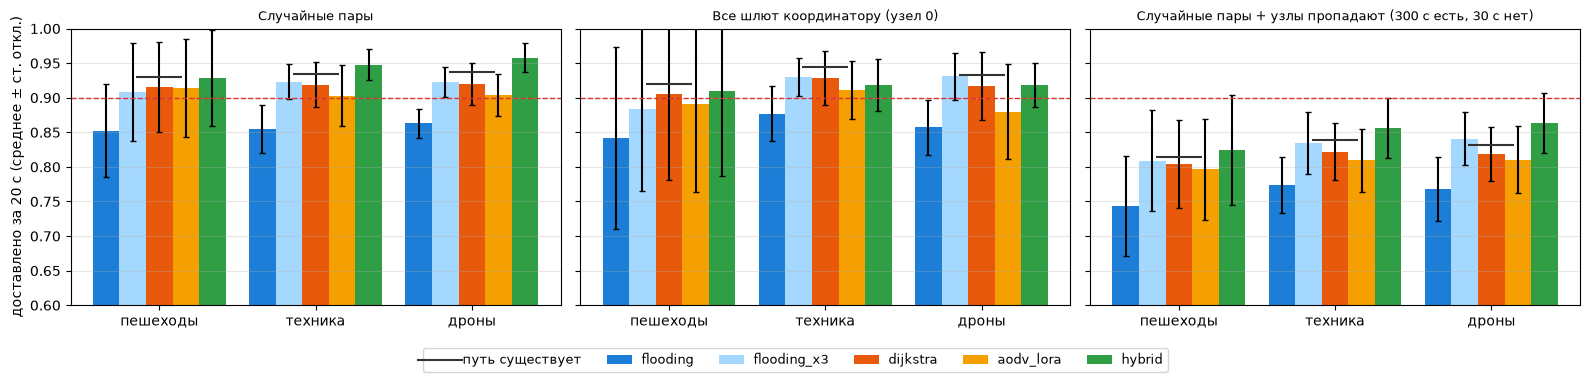

In [22]:
# EXP 11.2: главный результат
HYB_METHODS = ("flooding", "flooding_x3", "dijkstra", "aodv_lora", "hybrid")
CASES = [("random", False, "Случайные пары"), ("sink", False, "Все шлют координатору (узел 0)"),
         ("random", True, "Случайные пары + узлы пропадают (300 с есть, 30 с нет)")]
SPECS_HMAIN = grid(HYB_METHODS, range(1, 21), topo=list(MOBILITY), pattern=["random", "sink"],
                   rate=[0.2], churn=[False, True])
SPECS_HMAIN = [s for s in SPECS_HMAIN if not (s["pattern"] == "sink" and s["churn"])]
df_hmain = run_grid("11_2_main", SPECS_HMAIN)

for pat, churn, title in CASES:
    sub = df_hmain[(df_hmain.pattern == pat) & (df_hmain.churn == churn)]
    print(title)
    display(criteria_table(sub.assign(topo=sub.topo.map(MOBILITY))))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (pat, churn, title) in zip(axes, CASES):
    sub = df_hmain[(df_hmain.pattern == pat) & (df_hmain.churn == churn)]
    xs = list(MOBILITY)
    w = 0.85 / len(HYB_METHODS)
    for i, m in enumerate(HYB_METHODS):
        s = sub[sub.method == m].groupby("topo").pdr_20s
        ax.bar([j + (i - (len(HYB_METHODS) - 1) / 2) * w for j in range(len(xs))], s.mean().reindex(xs), w,
               yerr=s.std().reindex(xs), capsize=2, label=m, color=METHOD_COLORS[m])
    reach = sub.groupby("topo").reachable_share.mean().reindex(xs)
    ax.scatter(range(len(xs)), reach, marker="_", s=1100, color="#333", zorder=5, label="путь существует")
    ax.axhline(1 - LOSS_MAX, color="#e03131", ls="--", lw=1)
    ax.set_xticks(range(len(xs))); ax.set_xticklabels([MOBILITY[x] for x in xs]); ax.set_ylim(0.6, 1.0)
    ax.set_title(title, fontsize=9); ax.grid(axis="y", alpha=.3)
axes[0].set_ylabel("доставлено за 20 с (среднее ± ст. откл.)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, fontsize=9)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

**Итог 11.2.**

| Сценарий | Гибрид | Эталон Дейкстры | Требование |
|---|---|---|---|
| Случайные пары: пешеходы / техника / дроны | **0,928 / 0,948 / 0,958** | 0,916–0,920 | для техники и дронов выполнено уверенно, для пешеходов в среднем выполнено, но интервал задевает порог |
| Трафик к координатору | 0,909–0,919 | 0,906–0,929 | на уровне эталона |
| Пропадание узлов | **0,825–0,863** | 0,804–0,822 | не выполняет никто: сеть распадается в 16–19 % случаев |

- **Гибрид доставляет больше эталона Дейкстры с полной картой сети.** У техники и дронов потери (4–5 %) даже меньше доли пакетов без пути в момент отправки (6–7 %).
- **Тройное затопление** (0,909–0,923) уступает гибриду и тратит в 1,5–1,8 раза больше эфира: 3,4 с против 1,9–2,3 с на пакет.
- **Задержка** в среднем 3,3–3,8 с против 4,4–5,1 с у `aodv_lora`, p95 — 11–14 с. Требование 20 с выполнено.
- **Эфир** при случайных парах как у `aodv_lora`. При трафике к координатору на 20–30 % больше: 2,1–3,2 с.

### 11.3. Почему гибрид обгоняет эталон

Делим пакеты на две группы по тому, существовал ли путь в момент отправки (оракул), и смотрим долю доставленных за 20 с в каждой.

Отдельно считаем, сколько пакетов дошло прямо внутри RREQ. Это работа механизма 1.

In [23]:
# EXP 11.3: где гибрид выигрывает — пакеты с путём и без пути в момент отправки
rows = []
for topo in MOBILITY:
    for churn in (False, True):
        for m in ("flooding_x3", "dijkstra", "aodv_lora", "hybrid"):
            pk_all, in_rreq, gen = [], 0, 0
            for seed in range(1, 6):
                res, sim = simulate(make_scenario(topo, churn=churn), m, seed)
                pk = sim.packets_df()
                pk_all.append(pk)
                in_rreq += res.get("delivered_in_rreq", 0) or 0
            pk = pd.concat(pk_all)
            ok = (pk.outcome == "delivered") & (pk.latency_s <= DEADLINE_S)
            reach = pk.reachable.astype(bool)
            rows.append({"движение": MOBILITY[topo], "узлы пропадают": "да" if churn else "нет", "метод": m,
                         "путь был: доставлено": ok[reach].mean(),
                         "пути не было: доставлено": ok[~reach].mean(),
                         "пакетов без пути, %": 100 * (~reach).mean(),
                         "доставлено внутри RREQ, % от доставленных": 100 * in_rreq / max(ok.sum(), 1) if m == "hybrid" else float("nan")})
t_why = pd.DataFrame(rows).round(3)
t_why

,движение,узлы пропадают,метод,путь был: доставлено,пути не было: доставлено,"пакетов без пути, %","доставлено внутри RREQ, % от доставленных"
0,пешеходы,нет,flooding_x3,0.980,0.167,3.103,NaN
1,пешеходы,нет,dijkstra,0.977,0.000,3.103,NaN
2,пешеходы,нет,aodv_lora,0.982,0.167,3.103,NaN
3,пешеходы,нет,hybrid,0.996,0.167,3.103,77.798
4,пешеходы,да,flooding_x3,0.971,0.157,15.543,NaN
5,пешеходы,да,dijkstra,0.978,0.000,15.543,NaN
6,пешеходы,да,aodv_lora,0.911,0.241,15.543,NaN
7,пешеходы,да,hybrid,0.953,0.301,15.543,78.242
8,техника,нет,flooding_x3,0.976,0.302,7.414,NaN
9,техника,нет,dijkstra,0.991,0.000,7.414,NaN


**Итог 11.3.** Гибрид выигрывает в обеих группах пакетов.
- **Путь был:** гибрид доставляет 0,95–1,00 против 0,89–0,98 у `aodv_lora`. Пакет едет вместе с поиском, и не нужно, чтобы поиск, ответ и передача данных успели пройти, пока путь не порвался.
- **Пути не было:** гибрид доставляет 17–75 % таких пакетов. Эталон Дейкстры — 0 %: без пути он пакет сразу теряет. Повторный поиск везёт пакет снова, и если сеть за эти секунды соединилась, пакет доходит.
- **78–85 % доставленных пакетов доехали прямо внутри RREQ.** При случайных парах гибрид фактически работает как затопление с повтором до подтверждения.

### 11.4. Вклад каждого механизма

Парное сравнение с `hybrid` на одинаковых сценариях (случайные пары и трафик к координатору, по 10 повторов):
- убрать механизм 1;
- убрать механизм 2;
- вернуть 2 повтора поиска;
- «быстрый режим» — кольцо начинается с известной длины пути.

На графике изменение доли доставленных за 20 с, 95 % интервал. Рядом — изменение эфира и задержки.

hybrid: доставлено за 20 с 0.941, эфир 2.39 с, задержка 3.29 с


,Δ доставлено за 20 с,± 95 %,"эфир на пакет, с","задержка ср., с"
вариант,,,,
− пакет в RREQ,-0.031,0.009,1.979,4.157
− храни и неси,-0.008,0.004,2.433,3.216
"− оба (= aodv_lora, 1 повтор)",-0.032,0.009,1.977,4.140
2 повтора поиска,-0.004,0.007,2.543,3.457
быстрый режим,-0.017,0.007,3.120,2.741


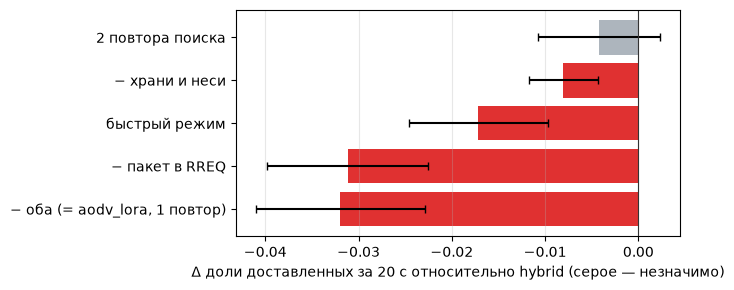

In [24]:
# EXP 11.4: вклад механизмов гибрида (парное сравнение)
V_HABL = {
    "hybrid": {},
    "− пакет в RREQ": dict(piggyback=False),
    "− храни и неси": dict(carry=False),
    "− оба (= aodv_lora, 1 повтор)": dict(piggyback=False, carry=False),
    "2 повтора поиска": dict(rreq_retries=2),
    "быстрый режим": dict(ring_from_known_hops=True),
}
SPECS_HABL = variants(V_HABL, range(1, 11), base="hybrid", topo=list(MOBILITY), pattern=["random", "sink"], rate=[0.2])
df_habl = run_grid("11_4_ablation", SPECS_HABL)

_key = ["topo", "pattern", "seed"]
ref = df_habl[df_habl.method == "hybrid"].set_index(_key)
rows = []
for v in V_HABL:
    if v == "hybrid":
        continue
    x = df_habl[df_habl.method == v].set_index(_key)
    d = (x.pdr_20s - ref.pdr_20s).dropna()
    rows.append({"вариант": v, "Δ доставлено за 20 с": d.mean(), "± 95 %": 1.96 * d.std() / len(d) ** 0.5,
                 "эфир на пакет, с": x.airtime_per_delivered_s.mean(), "задержка ср., с": x.latency_mean_s.mean()})
t_habl = pd.DataFrame(rows).set_index("вариант")
print(f"hybrid: доставлено за 20 с {ref.pdr_20s.mean():.3f}, эфир {ref.airtime_per_delivered_s.mean():.2f} с, "
      f"задержка {ref.latency_mean_s.mean():.2f} с")
display(t_habl.round(3))

fig, ax = plt.subplots(figsize=(7, 3))
tt = t_habl.sort_values("Δ доставлено за 20 с")
ax.barh(tt.index, tt["Δ доставлено за 20 с"], xerr=tt["± 95 %"], capsize=3,
        color=["#adb5bd" if abs(m) <= c else ("#2f9e44" if m > 0 else "#e03131")
               for m, c in zip(tt["Δ доставлено за 20 с"], tt["± 95 %"])])
ax.axvline(0, color="#333", lw=.8); ax.grid(axis="x", alpha=.3)
ax.set_xlabel("Δ доли доставленных за 20 с относительно hybrid (серое — незначимо)")
plt.tight_layout(); plt.show()

**Итог 11.4.**
- **Первый пакет в RREQ** — главный механизм: без него −0,031 ± 0,009.
- **«Храни и неси»** даёт небольшой, но значимый плюс: +0,008 ± 0,004, при почти том же эфире. Он же позволяет обойтись одним повтором поиска вместо двух.
- **Второй повтор поиска** ничего не добавляет, но стоит +6 % эфира.
- **«Быстрый режим»** (кольцо сразу на известную длину пути) снижает среднюю задержку с 3,3 до 2,7 с, но теряет 0,017 доставки и тратит на 30 % больше эфира. Включать его стоит, только если задержка важнее надёжности.

### 11.5. Цена: доставка против эфира

Каждая точка — метод в одном из сценариев 11.2, среднее по повторам. Лучше всего быть вверху слева: доставлено много, эфира потрачено мало. Пунктир соединяет точки одного метода.

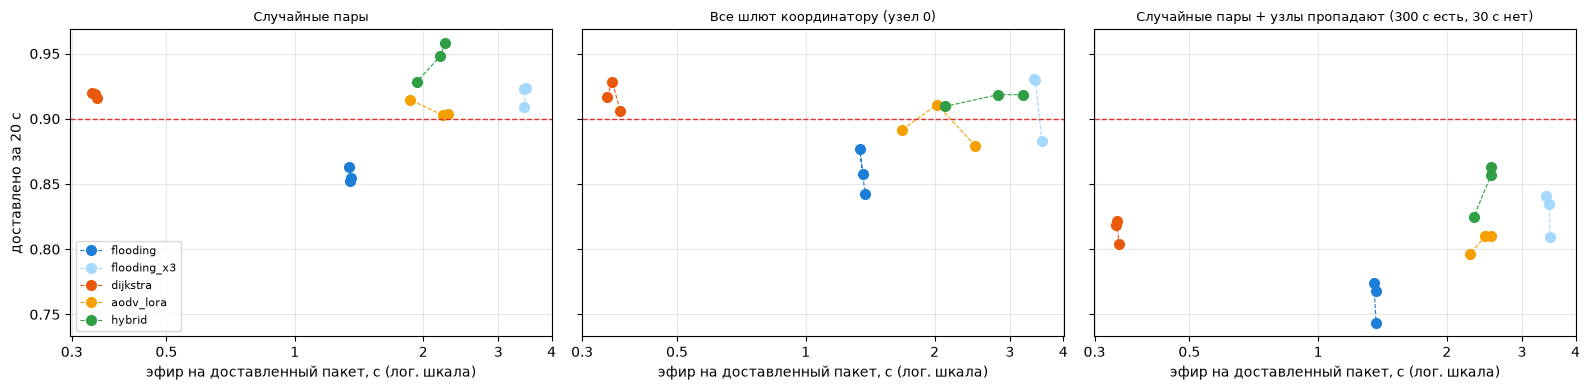

,доставлено за 20 с (ср. по сценариям),"эфир на пакет, с","задержка ср., с"
method,,,
flooding,0.826,1.355,0.352
flooding_x3,0.887,3.464,0.968
dijkstra,0.884,0.344,0.300
aodv_lora,0.869,2.205,4.468
hybrid,0.903,2.436,3.481


In [25]:
# EXP 11.5: доставка против расхода эфира
agg = df_hmain.groupby(["method", "pattern", "churn", "topo"]).agg(
    pdr=("pdr_20s", "mean"), air=("airtime_per_delivered_s", "mean"), lat=("latency_mean_s", "mean")).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (pat, churn, title) in zip(axes, CASES):
    sub = agg[(agg.pattern == pat) & (agg.churn == churn)]
    for m in HYB_METHODS:
        s = sub[sub.method == m]
        ax.plot(s.air, s.pdr, "o--", color=METHOD_COLORS[m], label=m, ms=7, lw=0.8)
    ax.axhline(1 - LOSS_MAX, color="#e03131", ls="--", lw=1)
    ax.set_xscale("log"); ax.minorticks_off()
    ticks = [0.3, 0.5, 1, 2, 3, 4]
    ax.set_xticks(ticks); ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.set_xlabel("эфир на доставленный пакет, с (лог. шкала)")
    ax.set_title(title, fontsize=9); ax.grid(alpha=.3)
axes[0].set_ylabel("доставлено за 20 с"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

summary = agg.groupby("method").agg(pdr=("pdr", "mean"), air=("air", "mean"), lat=("lat", "mean")).reindex(HYB_METHODS)
summary.columns = ["доставлено за 20 с (ср. по сценариям)", "эфир на пакет, с", "задержка ср., с"]
summary.round(3)

**Итог 11.5.** По всем сценариям 11.2 в среднем:

| Метод | Доставлено за 20 с | Эфир на пакет, с |
|---|---|---|
| **`hybrid`** | **0,903** | 2,4 |
| `flooding_x3` | 0,887 | 3,5 |
| `dijkstra` (оракул) | 0,884 | 0,34 |
| `aodv_lora` | 0,869 | 2,2 |

Из реализуемых методов гибрид даёт лучшую доставку. Эталон Дейкстры дешевле по эфиру в 7 раз, но в реальной сети его нет: полную карту подвижной сети пришлось бы рассылать постоянно.

### 11.6. Нагрузка

Слабое место `aodv_lora` — нагрузка: при 0,5 пакета/с доставка падает до 0,53–0,62. Проверяем, как держится гибрид. Пакет внутри RREQ делает каждую волну поиска тяжелее, но может и разгрузить сеть: часть пакетов доходит без отдельной адресной передачи.

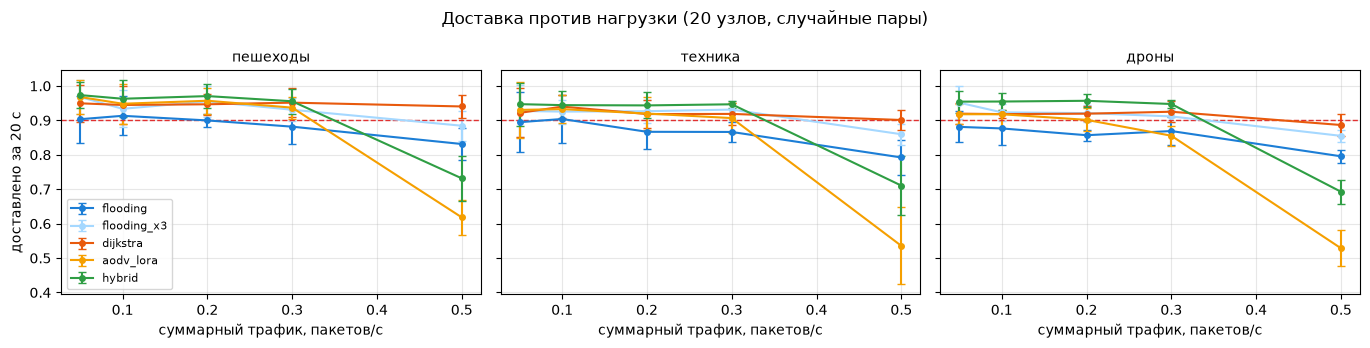

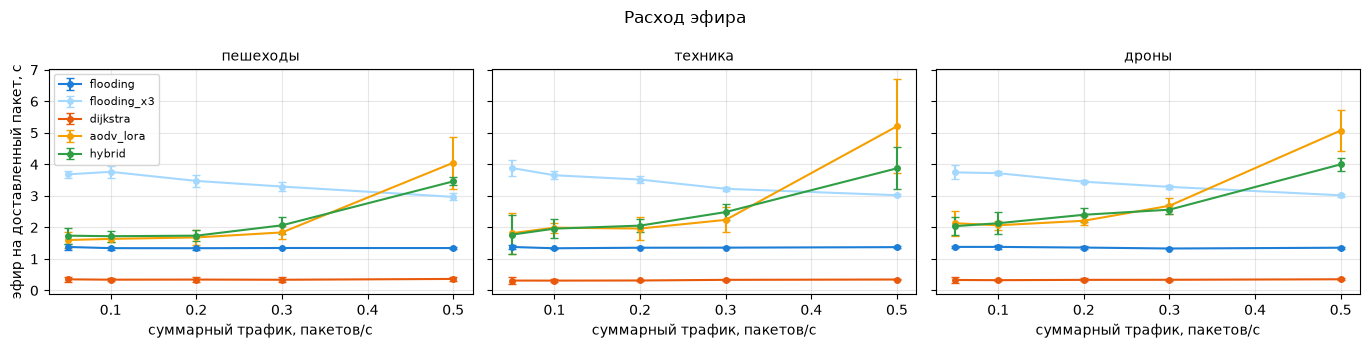

Наибольшая нагрузка из проверенных (пакетов/с на всю сеть), при которой потери за 20 с ≤ 10 % (NaN — ни при какой):


topo,пешеходы,техника,дроны
method,,,
flooding,0.1,0.1,NaN
flooding_x3,0.3,0.3,0.3
dijkstra,0.5,0.5,0.3
aodv_lora,0.3,0.3,0.2
hybrid,0.3,0.3,0.3


In [26]:
# EXP 11.6: нагрузка
RATES = [0.05, 0.1, 0.2, 0.3, 0.5]
SPECS_HLOAD = grid(HYB_METHODS, range(1, 6), topo=list(MOBILITY), pattern=["random"], rate=RATES)
df_hload = run_grid("11_6_load", SPECS_HLOAD)
plot_lines(df_hload, "rate", "pdr_20s", target=1 - LOSS_MAX, xlabel="суммарный трафик, пакетов/с",
           ylabel="доставлено за 20 с", title="Доставка против нагрузки (20 узлов, случайные пары)")
plot_lines(df_hload, "rate", "airtime_per_delivered_s", xlabel="суммарный трафик, пакетов/с",
           ylabel="эфир на доставленный пакет, с", title="Расход эфира")
_m = df_hload.groupby(["method", "topo", "rate"]).pdr_20s.mean().reset_index()
cap = (_m[_m.pdr_20s >= 1 - LOSS_MAX].groupby(["method", "topo"]).rate.max().unstack()
       .reindex(index=list(HYB_METHODS), columns=list(MOBILITY)).rename(columns=MOBILITY))
print("Наибольшая нагрузка из проверенных (пакетов/с на всю сеть), при которой потери за 20 с ≤ 10 % (NaN — ни при какой):")
cap

**Итог 11.6.**
- **До 0,3 пакета/с** на всю сеть гибрид доставляет ≥ 0,94 при любом движении. Это лучший результат среди всех методов, включая эталон.
- **При 0,5 пакета/с** гибрид падает до 0,69–0,73. Это лучше `aodv_lora` (0,53–0,62), но хуже тройного затопления (0,86–0,88) и эталона (0,89–0,94). Причина та же: каждая новая пара — это затопление RREQ, теперь ещё и с данными. Как это исправить — в выводах.

### 11.7. Размер и плотность сети

Условия как в 10.8 исследования AODV, движение — техника (8–15 м/с):
- 10, 15 и 20 узлов при той же плотности;
- 20 узлов на 1500 × 1500 м (гуще) и на 2500 × 2500 м (реже).

In [27]:
# EXP 11.7: размер и плотность сети (техника)
SPECS_HSIZE = []
for n in (10, 15, 20):
    SPECS_HSIZE += grid(HYB_METHODS, range(1, 6), topo=["rwp20_vehicle"], n=[n], area=[round(2000 * (n / 20) ** 0.5)],
                        pattern=["random"], rate=[0.2])
for area in (1500, 2500):
    SPECS_HSIZE += grid(HYB_METHODS, range(1, 6), topo=["rwp20_vehicle"], n=[20], area=[area], pattern=["random"], rate=[0.2])
df_hsize = run_grid("11_7_size", SPECS_HSIZE)
df_hsize["конфигурация"] = df_hsize.apply(lambda r: f"{int(r.n)} узлов, {int(r.area)} × {int(r.area)} м", axis=1)
criteria_table(df_hsize, by=("конфигурация", "method"))

доставлено за 20 с  ± 95 %  потери, %  из них распад сети, %  задержка ср., с  задержка p95, с  эфир на пакет, с потери ≤ 10 %
конфигурация            method                                                                                                                                     
10 узлов, 1414 × 1414 м flooding                  0.906   0.023      9.445                  4.137            0.211            0.562             0.638  ≈ на границе
                        flooding_x3               0.956   0.015      4.429                  4.137            0.630            3.433             1.733             ✅
                        dijkstra                  0.943   0.028      5.731                  4.137            0.194            0.508             0.226             ✅
                        aodv_lora                 0.973   0.026      2.661                  4.137            2.442            8.172             0.884             ✅
                        hybrid                    0.979   0.007      2.132                  4.137            1.788            6.357             0.817             ✅
15 узлов, 1732 × 1732 м flooding                  0.879   0.033     12.098                  5.726            0.277            0.727             0.992  ≈ на границе
                        flooding_x3               0.927   0.033      7.273                  5.726            0.802            3.898             2.625  ≈ на границе
                        dijkstra                  0.933   0.031      6.696                  5.726            0.247            0.631             0.280             ✅
                        aodv_lora                 0.934   0.028      6.598                  5.726            3.439           11.710             1.406             ✅
                        hybrid                    0.964   0.033      3.649                  5.726            2.715           11.018             1.469             ✅
20 узлов, 2000 × 2000 м flooding                  0.867   0.044     13.329                  7.334            0.337            0.873             1.355  ≈ на границе
                        flooding_x3               0.927   0.030      7.347                  7.334            0.971            4.648             3.517  ≈ на границе
                        dijkstra                  0.918   0.036      8.173                  7.334            0.281            0.715             0.316  ≈ на границе
                        aodv_lora                 0.920   0.043      8.030                  7.334            4.346           13.012             1.964  ≈ на границе
                        hybrid                    0.943   0.033      5.659                  7.334            3.084            9.882             2.056             ✅
20 узлов, 1500 × 1500 м flooding                  0.928   0.016      7.200                  1.387            0.241            0.675             1.359             ✅
                        flooding_x3               0.972   0.008      2.760                  1.387            0.765            4.138             3.580             ✅
                        dijkstra                  0.976   0.013      2.415                  1.387            0.202            0.536             0.234             ✅
                        aodv_lora                 0.981   0.014      1.914                  1.387            3.148           10.015             1.498             ✅
                        hybrid                    0.990   0.010      1.047                  1.387            1.921            6.751             1.629             ✅
20 узлов, 2500 × 2500 м flooding                  0.742   0.057     25.760                 19.165            0.394            0.923             1.319             ❌
                        flooding_x3               0.805   0.052     19.543                 19.165            1.058            3.962             3.311             ❌
                        dijkstra                  0.772   0.052     22.782                 19.165    

**Итог 11.7.** Гибрид лучший во всех конфигурациях.

| Конфигурация | Гибрид | Комментарий |
|---|---|---|
| 10 узлов | 0,979 | |
| 15 узлов | 0,964 | |
| 20 узлов, 2 × 2 км | 0,943 | |
| 20 узлов, 1,5 × 1,5 км | 0,990 | |
| 20 узлов, 2,5 × 2,5 км | 0,825 | требование не выполнено, но это выше доли пакетов, для которых путь существовал (0,808) |

### 11.8. Ресурсы узла и задержка

method,aodv_lora,hybrid
"ОЗУ под маршрутизацию, байт",3136.000,3136.000
макс. записей в таблице маршрутов,19.000,19.000
макс. пакетов в буфере ожидания,6.000,8.000
макс. длина очереди передачи,14.000,17.000
перезаписей ПЗУ за 5 лет (номер блоками по 1024),11035.547,10008.984
макс. доля эфира узла,0.042,0.056
макс. загрузка MCU,0.012,0.013
"ОЗУ, % от 200 кБ",1.531,1.531


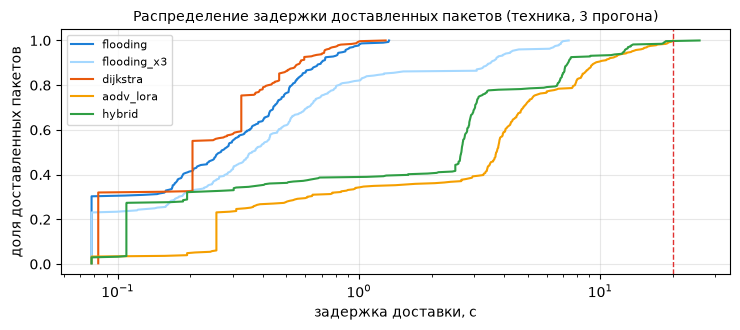

In [28]:
# EXP 11.8: ресурсы узла и распределение задержки
res_h = df_hmain[df_hmain.method.isin(["aodv_lora", "hybrid"])].groupby("method").agg(
    ram_bytes=("ram_bytes", "max"), peak_routes=("peak_routes", "max"), peak_pending=("peak_pending", "max"),
    peak_queue=("peak_queue", "max"), flash_writes_5y=("flash_writes_5y", "max"),
    max_node_duty=("max_node_duty", "max"), mcu_util_max=("mcu_util_max", "max"))
res_h["ОЗУ, % от 200 кБ"] = 100 * res_h.ram_bytes / RAM_MAX_B
res_h = res_h.rename(columns={
    "ram_bytes": "ОЗУ под маршрутизацию, байт", "peak_routes": "макс. записей в таблице маршрутов",
    "peak_pending": "макс. пакетов в буфере ожидания", "peak_queue": "макс. длина очереди передачи",
    "flash_writes_5y": "перезаписей ПЗУ за 5 лет (номер блоками по 1024)",
    "max_node_duty": "макс. доля эфира узла", "mcu_util_max": "макс. загрузка MCU"})
display(res_h.round(3).T)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for m in HYB_METHODS:
    lat = []
    for seed in range(1, 4):
        _, sim = simulate(make_scenario("rwp20_vehicle"), m, seed)
        lat += sim.packets_df().latency_s.dropna().tolist()
    lat = sorted(lat)
    ax.plot(lat, [i / len(lat) for i in range(1, len(lat) + 1)], label=m, color=METHOD_COLORS[m])
ax.axvline(DEADLINE_S, color="#e03131", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("задержка доставки, с"); ax.set_ylabel("доля доставленных пакетов")
ax.set_title("Распределение задержки доставленных пакетов (техника, 3 прогона)", fontsize=10)
ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Итог 11.8.** Ресурсы те же, что у `aodv_lora`:
- **ОЗУ:** ~3 кБ, 1,5 % от 200 кБ. Пакет-пассажир берётся из того же буфера ожидания.
- **ПЗУ:** ~10 тыс. перезаписей за 5 лет при записи номера блоками.
- **Эфир узла:** до 5,6 % времени при лимите 10 %.
- **Микроконтроллер:** загружен на 1,3 %.

## 12. Выводы

**1. Гибрид** = `aodv_lora` + первый пакет внутри RREQ + «храни и неси». Он **доставляет больше эталона Дейкстры**, у которого полная карта сети. 20 подвижных узлов, случайные пары, 0,2 пакета/с:

| Движение | Гибрид | Эталон | `aodv_lora` |
|---|---|---|---|
| Пешеходы | 0,928 | 0,916 | 0,915 |
| Техника | 0,948 | 0,919 | 0,903 |
| Дроны | 0,958 | 0,920 | 0,903 |

**2. Почему так.** Пока ответа нет, пакет едет вместе с каждой волной поиска. Как только пришёл RREP, источник знает, что пакет доставлен, и дальше шлёт адресно.
- Получается **затопление с повтором до подтверждения**. Оно надёжнее одиночного затопления и дешевле слепого повтора: тройное затопление доставляет меньше и тратит в 1,5–1,8 раза больше эфира.
- Повторные поиски и «храни и неси» доставляют часть пакетов, для которых в момент отправки пути не было: узлы двигаются, и за 20 с сеть часто снова соединяется.

**3. Требования** (до 20 подвижных узлов, 2 × 2 км, 0,2 пакета/с):

| Требование | Гибрид |
|---|---|
| Потери ≤ 10 % | ✅ техника и дроны, с запасом: 4–5 %; ≈ пешеходы: 7 % в среднем, интервал задевает порог |
| Задержка ≤ 20 с | ✅ в среднем 3–4 с, p95 = 11–14 с |
| ОЗУ 200 кБ | ✅ ~3 кБ |
| ПЗУ ≤ 100 000 перезаписей за 5 лет | ✅ ~10 тыс. |

В более плотной сети и при 10–15 узлах потери 1–4 %.

**4. Ограничения.**
- **Нагрузка:** требования держатся до 0,3 пакета/с на всю сеть, при 0,5 доставка падает до 0,7.
- **Пропадание узлов:** при 300 с работы и 30 с отсутствия требование не выполняет никто, хотя гибрид и тут лучший (0,83–0,86).
- **Длинные неподвижные цепочки слабых каналов:** RREQ без подтверждений теряется.
- **Трафик к координатору:** эфира на 20–30 % больше, чем у `aodv_lora`.

**5. Что дальше.**
- **Переключение по загрузке канала.** Узел видит, насколько занят эфир. При высокой загрузке он перестаёт класть данные в RREQ и использует кольцо с известной длины пути. Цель — убрать провал при 0,5 пакета/с.
- **Надёжный RREQ на цепочках.** Если ретранслятор не услышал, что сосед переслал его RREQ дальше, он повторяет RREQ один раз (пассивное подтверждение).
- **Повторы с нарастающей паузой** — изменение канального уровня из `aodv_lora`. Его стоит проверить в DSR и RL.
- **Проверка на реальных узлах SX1262**, начиная с 3–5 узлов.

**Ограничения модели** те же, что в исследовании AODV: «единичный диск» без эффекта захвата, движение Random Waypoint, синтетический трафик.